# 05 · Evaluación

**SIRAP** · Proyecto Integrador en IA (MIAR0545) · Eduardo Alejandro Ceballos Jijón · Christian Xavier Valle Maridueña

Evaluación del detector en *test* (umbrales calibrados en *val*, mAP por tamaño, ejemplos), velocidad, OCR con placas reales de SAVH Guayaquil, regla de decisión y resultados finales frente a las metas.

> Este notebook es un extracto de `SIRAP_backend.ipynb` (el notebook completo, que es la fuente de verdad). Las celdas y sus salidas son las mismas; la sección 0 se repite para que corra por sí solo en Colab.

## 0. Preparación

Esta sección deja lista la sesión de Colab: comprueba la GPU, instala las librerías, lee las llaves de API, monta Google Drive, define todas las rutas de entrada y fija la configuración del experimento. Hay que correrla completa al empezar cada sesión; no entrena ni evalúa nada.

### GPU
`nvidia-smi` muestra la GPU asignada. Si falla, ve a `Entorno de ejecución` → `Cambiar tipo de entorno de ejecución` → `GPU T4` y guarda. Sin GPU el notebook funciona, pero entrenar y evaluar los detectores se vuelve muy lento (el OCR corre en la CPU en cualquier caso).

In [ ]:
!nvidia-smi

Sat Oct 24 00:16:41 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   33C    P8             12W /   72W |       0MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### Dependencias
Instala solo las librerías que Colab no trae, en las versiones con las que se probó el notebook, para que los resultados se puedan reproducir:

- `ultralytics==8.4.177`: entrenamiento, validación e inferencia de YOLO11.
- `trackers==2.6.1`: OC-SORT, el seguidor de placas del pipeline de video.
- `supervision==0.30.9`: detecciones, anotación de video y mAP por tamaño de placa.
- `fast-plate-ocr==1.1.0` y `onnxruntime==1.31.0`: el OCR de placas (`cct-s-v2-global-model`) y el motor que lo corre en la CPU. fast-plate-ocr se instala sin sus dependencias (`--no-deps`): pide `opencv-python-headless`, que podría chocar con el `opencv-python` de Colab (dos paquetes para el mismo `cv2`), y las demás (`numpy`, `pyyaml`, `rich` y `tqdm`) ya vienen en Colab.
- `roboflow==1.7.1`: descarga del dataset.
- `Levenshtein`: distancia entre placas (regla de decisión y CER).
- `psycopg[binary]==3.3.6`: conexión con PostgreSQL, donde se carga la base de datos de la planta.

`torch`, `torchvision`, `opencv`, `pandas` y `matplotlib` ya vienen en Colab y no se tocan. Si al terminar Colab pide **reiniciar la sesión**, reinicia y sigue desde la celda siguiente (no hace falta reinstalar).

La celda de importaciones, más abajo, carga todas las librerías y muestra la GPU y las versiones instaladas.

In [ ]:
!pip install -q "ultralytics==8.4.177" "trackers==2.6.1" "supervision==0.30.9" "roboflow==1.7.1" Levenshtein "psycopg[binary]==3.3.6" "onnxruntime==1.31.0"
!pip install -q --no-deps "fast-plate-ocr==1.1.0"  # sin dependencias: usa el OpenCV que ya trae Colab

### Llaves de API (*Secrets* de Colab)

Las llaves no se escriben en el notebook: la función `get_secret` las lee del panel 🔑 **Secrets** de Colab (fuera de Colab, de variables de entorno).

| Secret | Para qué | ¿Obligatorio? |
|---|---|---|
| `ROBOFLOW_API_KEY` | Descargar el dataset de placas desde Roboflow (Roboflow → `Settings` → `API`) | Sí, con `DATASET_SOURCE = "roboflow"` |
| `PG_DSN` | Usar un servidor PostgreSQL propio (por ejemplo Supabase o Neon) en lugar del que el notebook instala en Colab | No (sección 6) |
| `CAMARA_URL` | Dirección de la cámara para el modo en vivo: la del túnel de Cloudflare (`https://….trycloudflare.com`) | No (sección 9) |
| `CAMARA_TOKEN` | Token que imprime `puente_camara.py` en la PC de la cámara | Con el puente (sección 9) |
| `CF_ACCESS_CLIENT_ID` y `CF_ACCESS_CLIENT_SECRET` | Token de servicio, si el túnel está protegido con Cloudflare Access | No (sección 9) |

En Colab: panel izquierdo → 🔑 **Secrets** → agrega cada nombre con su valor y activa el acceso desde el notebook.

> ⚠️ La v3.5 tenía dos llaves de Roboflow escritas en celdas, así que quedaron guardadas en el archivo y en cualquier copia que se haya compartido. **Revócalas en Roboflow (`Settings` → `API`), genera una nueva** y usa solo el *Secret*.

In [ ]:
import os


def get_secret(name: str, required: bool = False):
    """Lee un secreto de Colab (panel 🔑) o, fuera de Colab, de una variable de entorno."""
    try:
        from google.colab import userdata
        value = userdata.get(name)
    except ImportError:
        value = os.environ.get(name)
    except Exception:  # el secreto no existe o el notebook no tiene acceso
        value = None
    if required and not value:
        raise RuntimeError(f"Falta el secreto {name}: agrégalo en el panel 🔑 Secrets de Colab.")
    return value

In [ ]:
import csv
import copy
import gc
import hashlib
import json
import random
import re
import shutil
import subprocess
import time
import urllib.request
import zipfile
from importlib.metadata import version
from math import comb
from pathlib import Path

import cv2
import Levenshtein
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import supervision as sv
import torch
import yaml
from IPython.display import Image as IPyImage, Video, display
from PIL import Image, ImageDraw, ImageFont
from supervision.metrics import MeanAveragePrecision
from tqdm.auto import tqdm
from trackers import OCSORTTracker
from ultralytics import YOLO
from ultralytics.data.utils import IMG_FORMATS
from ultralytics.utils.torch_utils import get_flops, get_num_params

CUDA = torch.cuda.is_available()
DEVICE = 0 if CUDA else "cpu"
FP16 = 16 if CUDA else None  # inferencia en FP16 en la GPU (argumento `quantize` de Ultralytics 8.4)

print("GPU:", torch.cuda.get_device_name(0) if CUDA else "no disponible: todo será muy lento")
for package in ["torch", "ultralytics", "trackers", "supervision", "fast-plate-ocr", "onnxruntime"]:
    print(f"{package:<16}{version(package)}")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
GPU: NVIDIA L4
torch           2.11.0+cu130
ultralytics     8.4.177
trackers        2.6.1
supervision     0.30.9
fast-plate-ocr  1.1.0
onnxruntime     1.31.0


### Carpeta de trabajo en Google Drive
Colab borra `/content` al cerrar la sesión y entrenar el detector toma tiempo, así que todo se guarda en `MyDrive/proyecto_integrador_placas`. Si la sesión se cae a mitad de un entrenamiento, al volver a correr la celda de ese modelo **se reanuda desde la última época guardada**; y los resultados finales (sección 8) se pueden correr en otra sesión, porque lee todo desde aquí.

La celda siguiente monta Drive, define **todas** las rutas de entrada en un solo lugar y al final muestra cuáles encontró (`ok`, `vacío` o `no está`). Las que faltan no detienen el notebook: la sección que usa cada una se salta.

| Ruta en `MyDrive/proyecto_integrador_placas/` | Para qué | Sección |
|---|---|---|
| `savh_ground_truth_subset.zip` | 739 recortes de SAVH Guayaquil con la lectura de la cámara en `ground_truth.csv` | 5 |
| Hoja de Google **Revisión placas SAVH (142 legibles)** | Correcciones de esa referencia (se lee con tu cuenta de Google) | 5 |
| `revision_placas_142.csv` | Copia en CSV de la hoja, solo si no se puede leer la hoja (Archivo → Descargar → CSV) | 5 |
| `ocr/savh_ocr_salidas.csv` | Lecturas de GLM-OCR en SAVH que guardaron la v3.14 y anteriores: la sección 5 las compara con fast-plate-ocr | 5 |
| `authorized_plates.csv` | Placas autorizadas fuera de la base de la planta (excepciones), una por línea | 5 y 6 |
| `camiones_postgres.sql` | Base de la planta: vehículos, estado y transportista. Se carga en PostgreSQL | 6 |
| `video_camiones.mp4` | Video real del punto de control, con `USE_SAMPLE_VIDEO = False` | 6 |
| `video_ground_truth.csv` | Referencia anotada del video (placa e intervalo de cuadros) | 7a |
| `garita/imagenes/` y `garita/ground_truth.csv` | Imágenes completas de la garita con la placa transcrita | 7b |
| `dataset_placas_yolo.zip` | Dataset propio en formato YOLO, si `DATASET_SOURCE = "local"` | 1 |

`SAVH_Guayaquil_ANPR_Plate_Images_Dataset.zip` y `SAVH_YOLOv8CLS_Plate_Legibility_Dataset.zip.zip` también están en la carpeta, pero este notebook no los usa: el primero tiene las 2000 imágenes de las que sale el subconjunto, y el segundo es el dataset de legibilidad derivado de LPLCv2 (placas brasileñas). Tampoco usa `camiones.duckdb`, la misma base en DuckDB de versiones anteriores: la base de la planta se trabaja solo en PostgreSQL.

**Salidas.** Cada experimento escribe en `experimentos/<dataset>/`: `runs/` (entrenamientos y validaciones de Ultralytics), `resultados/` (métricas en JSON y CSV, y registros de decisiones), `figuras/` (gráficos para el informe) y `videos/` (videos anotados). La evaluación del OCR va a `ocr/`; la base de la planta se actualiza en su propio archivo, con una copia del original en `respaldo_bd/`. El modo en vivo (sección 9) guarda en `en_vivo/` el script del puente para la PC de la cámara y, por cada sesión, la grabación, el registro de decisiones y el resumen.

**Para retomar en una sesión nueva:** corre la sección 0 completa (no reentrena: los pesos ya están en Drive) y después las celdas que pide la sección que necesites, según la tabla de la portada (**Cómo usarlo**).

In [ ]:
USE_DRIVE = True  # guarda todo en Google Drive

WORK_DIR = Path("/content/proyecto_integrador_placas")
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        WORK_DIR = Path("/content/drive/MyDrive/proyecto_integrador_placas")
    except ImportError:
        print("Fuera de Colab: se usa una carpeta local.")
WORK_DIR.mkdir(parents=True, exist_ok=True)
print("Carpeta de trabajo:", WORK_DIR)

# ===================== Archivos de entrada (todas las rutas en un solo lugar) =====================
SAVH_ZIP_CANDIDATES = [WORK_DIR / "savh_ground_truth_subset.zip", Path("/content/savh_ground_truth_subset.zip")]
REVIEW_SHEET_ID = "1l79GrAYGFkTiOYxgKDT1_BEi_b-6Duo1_QqUNlcv7yM"  # hoja «Revisión placas SAVH (142 legibles)»
REVIEW_CSV_FALLBACK = WORK_DIR / "revision_placas_142.csv"        # copia en CSV de la hoja (opcional)
GLM_OCR_CACHE_PATH = WORK_DIR / "ocr" / "savh_ocr_salidas.csv"    # lecturas de GLM-OCR de la v3.14 (comparación)
AUTHORIZED_LIST_PATH = WORK_DIR / "authorized_plates.csv"
PLANT_POSTGRES_SQL_PATH = WORK_DIR / "camiones_postgres.sql"      # base de la planta (sección 6), se carga en PostgreSQL
REAL_VIDEO_PATH = WORK_DIR / "video_camiones.mp4"                 # video real del punto de control
VIDEO_GROUND_TRUTH_PATH = WORK_DIR / "video_ground_truth.csv"     # columnas: plate_gt, frame_start, frame_end
E2E_IMAGES_DIR = WORK_DIR / "garita" / "imagenes"                 # imágenes completas de la garita
E2E_GROUND_TRUTH_CSV = WORK_DIR / "garita" / "ground_truth.csv"   # columnas: image_path, plate_gt
LOCAL_DATASET_ZIP = WORK_DIR / "dataset_placas_yolo.zip"          # solo con DATASET_SOURCE = "local"
LIVE_DIR = WORK_DIR / "en_vivo"                                   # modo en vivo (sección 9): puente, grabaciones y registros
BRIDGE_SCRIPT_PATH = LIVE_DIR / "puente_camara.py"                # script para la PC de la cámara (celda 9.1)
LIVE_DIR.mkdir(exist_ok=True)


def input_status(path: Path) -> str:
    if not path.exists():
        return "no está"
    if path.is_file() and path.stat().st_size == 0:
        return "vacío"
    return "ok"


savh_zip_path = next((p for p in SAVH_ZIP_CANDIDATES if p.exists()), SAVH_ZIP_CANDIDATES[0])
display(pd.DataFrame(
    [{"entrada": label, "estado": input_status(path), "ruta": str(path)} for label, path in (
        ("SAVH: recortes y ground_truth.csv", savh_zip_path),
        ("Revisión de placas: copia CSV (opcional)", REVIEW_CSV_FALLBACK),
        ("SAVH: lecturas de GLM-OCR (comparación, opcional)", GLM_OCR_CACHE_PATH),
        ("Placas autorizadas (excepciones)", AUTHORIZED_LIST_PATH),
        ("Base de la planta: PostgreSQL", PLANT_POSTGRES_SQL_PATH),
        ("Video real", REAL_VIDEO_PATH),
        ("Referencia del video", VIDEO_GROUND_TRUTH_PATH),
        ("Imágenes de la garita", E2E_IMAGES_DIR),
        ("Referencia de la garita", E2E_GROUND_TRUTH_CSV),
        ("Dataset propio (YOLO)", LOCAL_DATASET_ZIP),
    )]).set_index("entrada"))
print("La hoja de revisión se lee en la sección 5 con tu cuenta de Google (ID " + REVIEW_SHEET_ID + ").")

Mounted at /content/drive
Carpeta de trabajo: /content/drive/MyDrive/proyecto_integrador_placas


,estado,ruta
entrada,,
SAVH: recortes y ground_truth.csv,ok,/content/drive/MyDrive/proyecto_integrador_pla...
Revisión de placas: copia CSV (opcional),no está,/content/drive/MyDrive/proyecto_integrador_pla...
"SAVH: lecturas de GLM-OCR (comparación, opcional)",no está,/content/drive/MyDrive/proyecto_integrador_pla...
Placas autorizadas (excepciones),vacío,/content/drive/MyDrive/proyecto_integrador_pla...
Base de la planta: PostgreSQL,ok,/content/drive/MyDrive/proyecto_integrador_pla...
Video real,ok,/content/drive/MyDrive/proyecto_integrador_pla...
Referencia del video,no está,/content/drive/MyDrive/proyecto_integrador_pla...
Imágenes de la garita,no está,/content/drive/MyDrive/proyecto_integrador_pla...
Referencia de la garita,no está,/content/drive/MyDrive/proyecto_integrador_pla...


La hoja de revisión se lee en la sección 5 con tu cuenta de Google (ID 1l79GrAYGFkTiOYxgKDT1_BEi_b-6Duo1_QqUNlcv7yM).


### Configuración

Todos los parámetros del experimento están en la celda siguiente, agrupados por tema:

- **Dataset:** origen (`DATASET_SOURCE`) y proyecto y versión de Roboflow.
- **Detector:** pesos iniciales, `batch` y argumentos de inferencia (`infer_kwargs`, vacío: YOLO11 usa el NMS por defecto de Ultralytics). `video_imgsz` es el tamaño al que el detector analiza el video, las imágenes de la garita y la cámara en vivo: 1280 px (la resolución de la cámara); la evaluación en *val* y *test* usa siempre 640, el tamaño de entrenamiento. `CONFIGS` tiene una entrada por configuración del detector, con el nombre que aparece en la base y en las tablas (y en el video, con `SHOW_VIDEO_TITLE = True`); la recorren las secciones 6, 7 y 9.
- **Entrenamiento:** preset, épocas, fracción de los datos, tamaño de imagen, paciencia del *early stopping* y semilla.
- **Umbrales:** piso del umbral calibrado y precisión mínima para decidir sin verificación manual; los umbrales mismos se calibran en la sección 3.
- **Seguimiento y OCR:** cuadros para confirmar un *track*, tamaños mínimos de placa para seguirla y para leerla, modelo de fast-plate-ocr y confianza mínima del OCR.
- **Control de acceso:** formatos válidos de placa.
- **Metas del proyecto:** mAP@0.5 ≥ 0,85, EMR ≥ 80 % y ≤ 1 s por imagen, que aparecen como líneas de referencia en los gráficos.
- **Carpetas de salida y utilidades** comunes: nombre de la corrida, cargar el detector y armar sus argumentos de inferencia (`detector_kwargs`), guardar y leer resultados en JSON.

**Protocolo de entrenamiento.** Dataset y splits fijos, tamaño de imagen 640, semilla 0, *early stopping* con paciencia 10 y lote efectivo de 64 imágenes: Ultralytics acumula gradientes hasta 64 imágenes por paso (`nbs=64`), así que `batch` solo cambia la memoria usada. Con este tamaño de dataset Ultralytics elige AdamW.

**Por qué YOLO11-s.** Es un detector pequeño (≈9,4 M de parámetros y ≈21 GFLOPs a 640 px; mAP@0.5:0.95 de 47,0 en COCO según Ultralytics) que corre rápido incluso en hardware modesto y se exporta a ONNX para correr en CPU dentro de la app. Las placas son una sola clase, mucho más simple que las 80 de COCO, y en *test* supera con holgura la meta de mAP@0.5 (sección 3). Otros tamaños: `yolo11n.pt`, más liviano, o `yolo11m.pt` y `yolo11l.pt`, más precisos en COCO.

**NMS.** YOLO11 propone varias cajas por objeto y se queda con la mejor mediante NMS (supresión de no máximos), con el umbral de solapamiento por defecto de Ultralytics (`iou=0.7`), igual al validar y al predecir. No tiene una cabeza sin NMS como la de YOLO26, el modelo de versiones anteriores de este notebook. Las latencias de la sección 4 incluyen el NMS, en el postproceso.

**Presets.** `rapido` entrena con una muestra aleatoria fija del 30 % de *train* y valida cada época con el 25 % de *val*, en 15 épocas: sirve para probar el flujo completo y tener números preliminares. `completo` usa todo con 40 épocas y es el que va al informe. Mira cuánto tarda la primera época antes de dejarlo corriendo: con las 2 CPU de Colab la carga de datos suele ser el cuello de botella.

**Umbrales.** Los umbrales de confianza no se fijan a mano: se calibran sobre *val* en la sección 3.


In [ ]:
# ===================== Dataset (detalles en la sección 1) =====================
DATASET_SOURCE = "roboflow"  # "roboflow" | "local"
RF_WORKSPACE = "roboflow-universe-projects"
RF_PROJECT = "license-plate-recognition-rxg4e"
RF_VERSION = 11
DATASET_ID = f"{RF_PROJECT}-v{RF_VERSION}" if DATASET_SOURCE == "roboflow" else LOCAL_DATASET_ZIP.stem

# ===================== Detector =====================
DETECTORS = {
    "YOLO11": {
        "loader": YOLO,
        "weights": "yolo11s.pt",         # yolo11n / s / m / l / x
        "batch": 16,
        "deterministic": True,
        "infer_kwargs": {},              # NMS por defecto de Ultralytics (iou=0.7): YOLO11 no tiene cabeza sin NMS
        "video_imgsz": 1280,             # video, garita y en vivo: la resolución de la cámara (a 640 no ve placas chicas)
    },
}
MODEL_COLORS = {"YOLO11": "#2a78d6"}  # color del modelo en todos los gráficos

# ===================== Configuraciones que corren el pipeline (secciones 6, 7 y 9) =====================
# etiqueta → (modelo, cambios en la inferencia, sufijo de los resultados). Una variante de inferencia
# (otros argumentos de predict) se agregaría aquí con su propio sufijo, sin tocar los resultados principales.
CONFIGS = {name: (name, None, "") for name in DETECTORS}

# ===================== Entrenamiento =====================
TRAINING_PRESET = "completo"  # "rapido" para probar el flujo · "completo" para el informe
PRESETS = {
    "rapido":   {"epochs": 15, "train_fraction": 0.30, "val_fraction": 0.25},
    "completo": {"epochs": 40, "train_fraction": 1.00, "val_fraction": 1.00},
}
EPOCHS = PRESETS[TRAINING_PRESET]["epochs"]
TRAIN_FRACTION = PRESETS[TRAINING_PRESET]["train_fraction"]
VAL_FRACTION = PRESETS[TRAINING_PRESET]["val_fraction"]
IMGSZ = 640
PATIENCE = 10          # early stopping: épocas seguidas sin mejorar en val
SEED = 0
WORKERS = 2            # Colab tiene 2 CPU
EVAL_BATCH = 16
FORCE_RETRAIN = False  # True borra el entrenamiento guardado de este preset y lo repite desde cero

# ===================== Umbrales de confianza (se calibran en la sección 3) =====================
CONF_FLOOR = 0.10                 # piso para el umbral calibrado
DECISION_PRECISION_TARGET = 0.95  # precisión mínima en val para aceptar una detección sin verificación manual

# ===================== Seguimiento y OCR (secciones 5 y 6) =====================
MINIMUM_CONSECUTIVE_FRAMES = 10
MIN_PLATE_AREA_RATIO = 0.001  # placas más chicas (fracción del frame) ni se siguen
OCR_PLATE_AREA_RATIO = 0.002  # tamaño mínimo para leer: en video_camiones.mp4 las placas de camiones detenidos miden 0,3–0,5 % del frame
OCR_MODEL_NAME = "cct-s-v2-global-model"  # fast-plate-ocr; "cct-xs-v2-global-model" es más chico y, en SAVH, algo menos preciso
OCR_CONF_MIN = None   # confianza mínima del OCR para decidir sin verificación manual; None = no se usa (sección 5)

# ===================== Control de acceso (sección 5) =====================
# Placas ecuatorianas: 3 letras + 3 o 4 dígitos. Con la revisión de placas, las 472 legibles de SAVH siguen uno
# de esos dos formatos. Los patrones de 2 letras + 4 o 5 dígitos de la v3.5 salían de errores de la cámara en la
# referencia (GB01825 es GBO-1825) y hacían que normalize_plate aceptara esas lecturas sin corregirlas.
PLATE_PATTERNS = [(3, 4), (3, 3)]  # (letras, dígitos), por frecuencia
# Para decidir, guardar y mostrar, las placas válidas se escriben XXX-0000 (format_plate, sección 5).

# ===================== Metas del proyecto (líneas de referencia en los gráficos) =====================
TARGET_MAP50 = 0.85
TARGET_EMR = 0.80
TARGET_E2E_S = 1.0

COLOR = sv.ColorPalette.from_hex([  # colores por track en los videos (de la v2)
    "#ffff00", "#ff9b00", "#ff66ff", "#3399ff", "#ff66b2", "#ff8080",
    "#b266ff", "#9999ff", "#66ffff", "#33ff99", "#66ff66", "#99ff00"
])

# ===================== Carpetas de salida (separadas por dataset) =====================
EXPERIMENT_DIR = WORK_DIR / "experimentos" / DATASET_ID
RUNS_DIR = EXPERIMENT_DIR / "runs"           # entrenamientos y validaciones de Ultralytics
RESULTS_DIR = EXPERIMENT_DIR / "resultados"  # métricas por modelo (JSON / CSV) y registros de decisiones
FIGURES_DIR = EXPERIMENT_DIR / "figuras"     # gráficos (PNG) para el informe
VIDEOS_DIR = EXPERIMENT_DIR / "videos"       # videos anotados
OCR_RESULTS_DIR = WORK_DIR / "ocr"           # evaluación del OCR en SAVH (no depende del detector)
for folder in (RUNS_DIR, RESULTS_DIR, FIGURES_DIR, VIDEOS_DIR, OCR_RESULTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)
print("Salidas de este experimento:", EXPERIMENT_DIR)


# ===================== Utilidades comunes =====================
def run_name(name: str) -> str:
    """Identificador de la corrida: modelo + pesos + preset, p. ej. 'YOLO11_yolo11s_rapido'."""
    return f"{name}_{Path(DETECTORS[name]['weights']).stem}_{TRAINING_PRESET}"


def best_weights_path(name: str) -> Path:
    return RUNS_DIR / run_name(name) / "weights" / "best.pt"


def trained_models() -> list:
    ready = [name for name in DETECTORS if best_weights_path(name).exists()]
    missing = [name for name in DETECTORS if name not in ready]
    if missing:
        print("Aviso: todavía sin entrenar en este preset:", ", ".join(missing))
    return ready


def load_detector(name: str):
    return DETECTORS[name]["loader"](str(best_weights_path(name)))


def detector_kwargs(name: str, override=None) -> dict:
    """Argumentos de inferencia del modelo (`infer_kwargs` en DETECTORS). `override` los cambia para una variante de
    CONFIGS; un valor None vuelve al valor por defecto de Ultralytics."""
    kwargs = {**DETECTORS[name]["infer_kwargs"], **(override or {})}
    return {key: value for key, value in kwargs.items() if value is not None}


def video_imgsz(name: str) -> int:
    """Tamaño de inferencia en el video, la garita y el modo en vivo (`video_imgsz` en DETECTORS; None = IMGSZ). La
    evaluación en val y test (secciones 3 y 4) usa siempre IMGSZ, el tamaño de entrenamiento."""
    return DETECTORS[name].get("video_imgsz") or IMGSZ


def _to_json(value):
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, Path):
        return str(value)
    raise TypeError(f"No se puede guardar {type(value)} en JSON")


def save_result(name: str, kind: str, data: dict) -> None:
    (RESULTS_DIR / f"{run_name(name)}_{kind}.json").write_text(json.dumps(data, indent=2, default=_to_json))


def load_result(name: str, kind: str):
    path = RESULTS_DIR / f"{run_name(name)}_{kind}.json"
    return json.loads(path.read_text()) if path.exists() else None


def free_gpu() -> None:
    gc.collect()
    if CUDA:
        torch.cuda.empty_cache()


def to_detections(result) -> sv.Detections:
    """Resultado de Ultralytics → sv.Detections en float32 (en FP16 las cajas llegan en float16)."""
    detections = sv.Detections.from_ultralytics(result)
    detections.xyxy = detections.xyxy.astype(np.float32)
    if detections.confidence is not None:
        detections.confidence = detections.confidence.astype(np.float32)
    return detections

Salidas de este experimento: /content/drive/MyDrive/proyecto_integrador_placas/experimentos/license-plate-recognition-rxg4e-v11


## 1. Dataset de detección de placas

El detector se entrena y evalúa con un dataset fijo y sus splits. Hay dos fuentes posibles:

- `DATASET_SOURCE = "roboflow"` (por defecto): **License Plate Recognition** de Roboflow Universe (`roboflow-universe-projects/license-plate-recognition-rxg4e`, versión 11: 10 125 imágenes — 7 057 *train*, 2 048 *val*, 1 020 *test* —, una clase, licencia CC BY 4.0). No es específico de Ecuador: sirve para aprender a detectar placas en general. En la celda de configuración puedes cambiar `RF_WORKSPACE`/`RF_PROJECT`/`RF_VERSION` por un proyecto propio.
- `DATASET_SOURCE = "local"`: un `.zip` propio en formato YOLO (`train/`, `valid/`, `test/` con `images/` y `labels/`, más `data.yaml`) en la carpeta de Drive, por ejemplo las imágenes de la garita anotadas en Roboflow y exportadas como *YOLOv8*.

**Para el informe:** lo ideal es que `test` tenga imágenes del dominio real (camiones en la garita). Un mAP alto en un test genérico no garantiza lo mismo con placas ecuatorianas.

La celda reescribe `data.yaml` con rutas absolutas (el de Roboflow trae rutas `../train/images` que no siempre se resuelven bien) y, en el preset `rapido`, crea las listas con la muestra aleatoria fija.

La celda imprime la carpeta del dataset y sus clases.

In [ ]:
# Disco local de Colab: leer miles de imágenes desde Drive en cada época sería mucho más lento.
DATASET_DIR = Path("/content/datasets") / DATASET_ID

# Obtener la clave de API de Roboflow desde los Secretos de Colab
ROBOFLOW_API_KEY = get_secret("ROBOFLOW_API_KEY")

def get_dataset() -> Path:
    """Descarga o descomprime el dataset (una sola vez por sesión) y devuelve la carpeta con data.yaml."""
    if not list(DATASET_DIR.rglob("data.yaml")):
        if DATASET_SOURCE == "roboflow":
            if not ROBOFLOW_API_KEY:
                raise RuntimeError("Falta el secreto ROBOFLOW_API_KEY (sección 0).")
            from roboflow import Roboflow
            DATASET_DIR.parent.mkdir(parents=True, exist_ok=True)
            project = Roboflow(api_key=ROBOFLOW_API_KEY).workspace(RF_WORKSPACE).project(RF_PROJECT)
            project.version(RF_VERSION).download("yolov8", location=str(DATASET_DIR), overwrite=True)
        elif DATASET_SOURCE == "local":
            with zipfile.ZipFile(LOCAL_DATASET_ZIP) as archive:
                archive.extractall(DATASET_DIR)
        else:
            raise ValueError("DATASET_SOURCE debe ser 'roboflow' o 'local'")
    return min(DATASET_DIR.rglob("data.yaml"), key=lambda p: len(p.parts)).parent


def write_data_yaml(root: Path) -> Path:
    """data.yaml con rutas absolutas y los splits que existan (Roboflow llama 'valid' al de validación)."""
    original = yaml.safe_load((root / "data.yaml").read_text())
    names = original.get("names", ["placa"])
    if isinstance(names, list):
        names = dict(enumerate(names))
    data = {"path": str(root.resolve()), "names": names}
    for key, candidates in {"train": ["train"], "val": ["valid", "val"], "test": ["test"]}.items():
        folder = next((c for c in candidates if (root / c / "images").is_dir()), None)
        if folder:
            data[key] = f"{folder}/images"
    if "test" not in data:
        print("Aviso: el dataset no trae split 'test'; se evaluará sobre val (no es lo ideal).")
        data["test"] = data["val"]
    if len(names) > 1:
        print(f"Aviso: el dataset tiene {len(names)} clases; el pipeline asume que todas son placas.")
    out = root / "data_abs.yaml"
    out.write_text(yaml.safe_dump(data, sort_keys=False, allow_unicode=True))
    return out


def list_images(folder: Path) -> list:
    return sorted(p for p in Path(folder).iterdir() if p.suffix[1:].lower() in IMG_FORMATS)


def write_subset_yaml(data_yaml: Path) -> Path:
    """Preset 'rapido': muestra aleatoria fija de train y val, la misma en cada corrida."""
    if TRAIN_FRACTION >= 1 and VAL_FRACTION >= 1:
        return data_yaml
    data = yaml.safe_load(data_yaml.read_text())
    root, rng = Path(data["path"]), random.Random(SEED)
    for key, fraction in (("train", TRAIN_FRACTION), ("val", VAL_FRACTION)):
        images = list_images(root / data[key])
        chosen = sorted(rng.sample(images, max(1, round(len(images) * fraction))))
        listing = root / f"{key}_{TRAINING_PRESET}.txt"
        listing.write_text("\n".join(str(p) for p in chosen) + "\n")
        data[key] = str(listing)
    out = root / f"data_{TRAINING_PRESET}.yaml"
    out.write_text(yaml.safe_dump(data, sort_keys=False, allow_unicode=True))
    return out


DATASET_ROOT = get_dataset()
DATA_YAML = write_data_yaml(DATASET_ROOT)       # evaluación: val y test completos
TRAIN_DATA_YAML = write_subset_yaml(DATA_YAML)  # entrenamiento: muestra fija en el preset 'rapido'
DATA = yaml.safe_load(DATA_YAML.read_text())
print("Dataset:", DATASET_ROOT, "| clases:", DATA["names"])

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/datasets/license-plate-recognition-rxg4e-v11 in yolov8:: 100%|██████████| 20262/20262 [00:02<00:00, 9061.05it/s] 


Dataset: /content/datasets/license-plate-recognition-rxg4e-v11 | clases: {0: 'License_Plate'}


## 3. Evaluación de la detección

Tres pasos:

1. **Calibración de umbrales en *val*.** `conf_track` es la confianza que maximiza F1: se usa en inferencia y en OC-SORT (`high_conf_det_threshold`). `conf_decision` es la menor confianza con precisión ≥ 95% en *val*: por debajo de ella la regla de acceso manda a verificación manual. (En la v2 el detector usaba 0,3, pero OC-SORT descartaba en silencio todo lo menor a 0,6.)
2. **Métricas en *test*** (el split que el modelo no vio): mAP@0.5, mAP@0.5:0.95, y precisión, recall y F1 **al umbral calibrado en *val*** — no al óptimo de *test*, para no ajustar con los datos de evaluación.
3. **mAP por tamaño de placa** (pequeña < 32², mediana < 96², grande ≥ 96² píxeles, criterio COCO) con `supervision`. Las placas lejanas son objetos pequeños, un caso históricamente difícil para los detectores. `supervision` interpola la curva precisión–recall al estilo COCO y Ultralytics de otra forma, así que su mAP global difiere un poco del de Ultralytics: usa este desglose para comparar tamaños de placa, y el mAP de Ultralytics como cifra principal.

La primera celda define las funciones y la segunda las corre con el modelo entrenado y muestra la tabla de resultados. Todo se guarda en `resultados/` (`*_umbrales.json`, `*_test.json`, `*_tamanos.json` y las curvas de *test* en `*_curvas_test.npz`, que usan los gráficos de la sección 8). En una sesión nueva, antes de esta sección hay que correr las secciones 0 y 1; los pesos entrenados se leen de Drive.

In [ ]:
# detector_kwargs (argumentos de inferencia del modelo) está en la celda de configuración.


def val_kwargs(name: str, split: str, suffix: str, plots: bool, override=None) -> dict:
    return dict(data=str(DATA_YAML), split=split, imgsz=IMGSZ, batch=EVAL_BATCH, conf=0.001, device=DEVICE,
                plots=plots, verbose=False, project=str(RUNS_DIR), name=f"{run_name(name)}_{suffix}",
                exist_ok=True, **detector_kwargs(name, override))


def mean_curve(curve) -> np.ndarray:
    """Promedio sobre clases de una curva de Ultralytics (clases × 1000 puntos)."""
    values = np.asarray(curve, dtype=float)
    return values.reshape(-1, 1000).mean(0) if values.size else np.zeros(1000)


def calibrate_thresholds(name: str, override=None, tag: str = "") -> dict:
    """Umbrales por modelo, calibrados sobre val (nunca sobre test). `override` y `tag` son para experimentos:
    cambian los argumentos de inferencia y el nombre con que se guardan los resultados."""
    metrics = load_detector(name).val(**val_kwargs(name, "val", f"calibracion{tag}", plots=False, override=override))
    conf = np.asarray(metrics.box.px, dtype=float)
    f1, precision, recall = (mean_curve(c) for c in (metrics.box.f1_curve, metrics.box.p_curve, metrics.box.r_curve))
    conf_track = float(max(conf[f1.argmax()], CONF_FLOOR))
    precise = np.where((conf >= conf_track) & (precision >= DECISION_PRECISION_TARGET) & (recall > 0))[0]
    conf_decision = float(conf[precise[0]]) if len(precise) else conf_track
    result = {"conf_track": conf_track, "conf_decision": conf_decision, "f1_max_val": float(f1.max()),
              "val_mAP50": float(metrics.box.map50), "val_mAP50-95": float(metrics.box.map)}
    save_result(name, f"umbrales{tag}", result)
    free_gpu()
    return result


def evaluate_on_test(name: str, thresholds: dict, override=None, tag: str = "") -> dict:
    metrics = load_detector(name).val(**val_kwargs(name, "test", f"test{tag}", plots=True, override=override))
    grid = np.asarray(metrics.box.px, dtype=float)
    p_curve, r_curve, f1_curve = (mean_curve(c) for c in (metrics.box.p_curve, metrics.box.r_curve, metrics.box.f1_curve))
    i = min(int(np.searchsorted(grid, thresholds["conf_track"])), len(grid) - 1)
    precision, recall = float(p_curve[i]), float(r_curve[i])
    result = {
        "mAP50": float(metrics.box.map50), "mAP50-95": float(metrics.box.map),
        "precision": precision, "recall": recall,
        "f1": 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
        "val_speed_ms": dict(metrics.speed), "carpeta": str(metrics.save_dir),
    }
    np.savez(RESULTS_DIR / f"{run_name(name)}_curvas_test{tag}.npz", grid=grid, f1=f1_curve, precision=p_curve,
             recall=r_curve, precision_at_recall=mean_curve(metrics.box.prec_values))
    save_result(name, f"test{tag}", result)
    free_gpu()
    return result


def map_by_size(name: str, override=None, tag: str = "") -> dict:
    """mAP calculado con supervision, desglosado por tamaño de placa (criterio COCO)."""
    model, predictions, targets = load_detector(name), [], []
    for result in model.predict(source=str(Path(DATA["path"]) / DATA["test"]), stream=True, conf=0.001,
                                imgsz=IMGSZ, device=DEVICE, verbose=False, **detector_kwargs(name, override)):
        height, width = result.orig_shape
        predictions.append(to_detections(result))
        targets.append(read_yolo_labels(label_path_for(Path(result.path)), width, height))
    metric = MeanAveragePrecision()
    metric.update(predictions, targets)
    res = metric.compute()

    def clean(x):  # supervision devuelve -1 cuando no hay placas de ese tamaño
        return float(x) if x is not None and x >= 0 else float("nan")

    result = {"sv_mAP50-95": clean(res.map50_95), "sv_mAP50": clean(res.map50),
              "mAP50-95_pequenas": clean(res.small_objects.map50_95),
              "mAP50-95_medianas": clean(res.medium_objects.map50_95),
              "mAP50-95_grandes": clean(res.large_objects.map50_95)}
    save_result(name, f"tamanos{tag}", result)
    free_gpu()
    return result

In [ ]:
detection_results = {}
for name in trained_models():
    print(f"=== {name} ===")
    thresholds = calibrate_thresholds(name)
    detection_results[name] = {**thresholds, **evaluate_on_test(name, thresholds), **map_by_size(name)}

columns = ["mAP50", "mAP50-95", "precision", "recall", "f1", "conf_track", "conf_decision",
           "mAP50-95_pequenas", "mAP50-95_medianas", "mAP50-95_grandes"]
if detection_results:
    display(pd.DataFrame(detection_results).T[columns].astype(float).round(3))

=== YOLO11 ===
Ultralytics 8.4.177 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 949.6±516.7 MB/s, size: 24.1 KB)
val: Scanning /content/datasets/license-plate-recognition-rxg4e-v11/valid/labels... 2048 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2048/2048 1.5Kit/s 1.4s
val: New cache created: /content/datasets/license-plate-recognition-rxg4e-v11/valid/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 128/128 11.2it/s 11.5s
                   all       2048       2195      0.986      0.948      0.972      0.691
Speed: 0.4ms preprocess, 3.0ms inference, 0.0ms loss, 0.7ms postprocess per image
Ultralytics 8.4.177 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs


,mAP50,mAP50-95,precision,recall,f1,conf_track,conf_decision,mAP50-95_pequenas,mAP50-95_medianas,mAP50-95_grandes
YOLO11,0.972,0.693,0.986,0.956,0.971,0.299,0.299,0.481,0.729,0.744


### Ejemplos visuales en *test*
Las mismas 4 imágenes de *test*, elegidas al azar con semilla fija, con la referencia (verde) y las detecciones de YOLO11 a su umbral calibrado, con la confianza de cada caja. Sirve para ver errores que el mAP resume en un número: placas perdidas, cajas de más o mal ajustadas. Se guarda en `figuras/ejemplos_test_<preset>.png`.

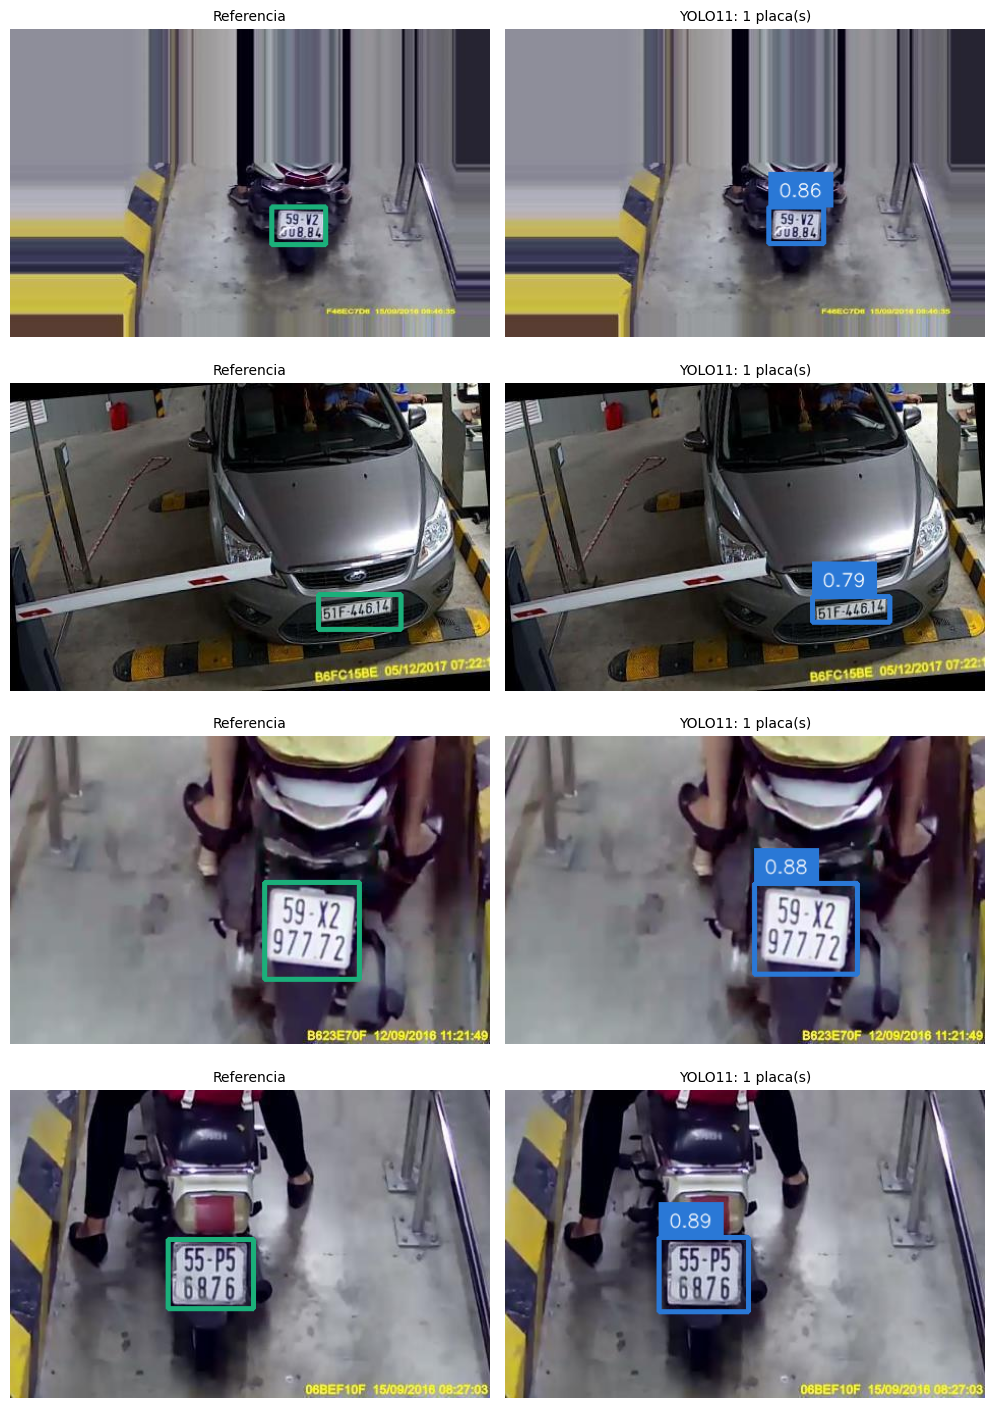

In [ ]:
VISUAL_SAMPLES = 4

models = [name for name in trained_models() if load_result(name, "umbrales")]  # con umbral ya calibrado
thresholds = {name: load_result(name, "umbrales") for name in models}
detectors = {name: load_detector(name) for name in models}
test_images = list_images(Path(DATA["path"]) / DATA["test"])
samples = random.Random(SEED).sample(test_images, min(VISUAL_SAMPLES, len(test_images)))
reference_annotator = sv.BoxAnnotator(color=sv.Color.from_hex("#1baf7a"), thickness=3)

fig, axes = plt.subplots(len(samples), 1 + len(models), figsize=(5 * (1 + len(models)), 3.6 * len(samples)), squeeze=False)
for row_axes, path in zip(axes, samples):
    image = cv2.imread(str(path))
    height, width = image.shape[:2]
    panels = [("Referencia", reference_annotator.annotate(image.copy(), read_yolo_labels(label_path_for(path), width, height)))]
    for name in models:
        result = detectors[name].predict(image, conf=thresholds[name]["conf_track"], imgsz=IMGSZ, device=DEVICE,
                                         verbose=False, **DETECTORS[name]["infer_kwargs"])[0]
        detections = to_detections(result)
        color = sv.Color.from_hex(MODEL_COLORS[name])
        panel = sv.BoxAnnotator(color=color, thickness=3).annotate(image.copy(), detections)
        panel = sv.LabelAnnotator(color=color, text_color=sv.Color.WHITE, text_scale=0.6).annotate(
            panel, detections, [f"{c:.2f}" for c in detections.confidence])
        panels.append((f"{name}: {len(detections)} placa(s)", panel))
    for ax, (title, panel) in zip(row_axes, panels):
        ax.imshow(cv2.cvtColor(panel, cv2.COLOR_BGR2RGB))
        ax.set_title(title, fontsize=10)
        ax.axis("off")
plt.tight_layout()
fig.savefig(FIGURES_DIR / f"ejemplos_test_{TRAINING_PRESET}.png", dpi=150)
plt.show()
del detectors
free_gpu()

## 4. Velocidad de inferencia

Latencia por imagen con lote de 1 (como en el video en vivo), en FP16 en la GPU, después de 10 inferencias de calentamiento, sobre 200 imágenes de *test*. Se reporta media, mediana y percentil 95, el desglose preproceso / inferencia / postproceso que entrega Ultralytics, y el tamaño del modelo tal como corre en inferencia (parámetros y GFLOPs a 640 px). El postproceso incluye el NMS.

Son tiempos en PyTorch. Exportar a TensorRT (o a ONNX, como hace la app de SIRAP para correr en CPU) cambia estos tiempos.

El detector corre con su `conf_track` calibrado en la sección 3 (leído de `*_umbrales.json`). Los resultados se guardan en `resultados/*_velocidad.json`. En una sesión nueva, antes de esta celda hay que correr las secciones 0 y 1.


In [ ]:
BENCHMARK_IMAGES = 200
WARMUP = 10


def benchmark_speed(name: str, images: list, override=None, tag: str = "") -> dict:
    model, thresholds = load_detector(name), load_result(name, f"umbrales{tag}")
    kwargs = dict(imgsz=IMGSZ, conf=thresholds["conf_track"] if thresholds else 0.25, device=DEVICE,
                  quantize=FP16, verbose=False, **detector_kwargs(name, override))
    for image in images[:WARMUP]:
        model.predict(image, **kwargs)
    latency, stages = [], {"preprocess": [], "inference": [], "postprocess": []}
    for image in images:
        if CUDA:
            torch.cuda.synchronize()
        start = time.perf_counter()
        result = model.predict(image, **kwargs)[0]
        if CUDA:
            torch.cuda.synchronize()
        latency.append((time.perf_counter() - start) * 1000)
        for stage in stages:
            stages[stage].append(result.speed[stage])

    network = model.predictor.model.model  # modelo fusionado, tal como corre en inferencia
    gflops = get_flops(network, imgsz=IMGSZ) or get_flops(copy.deepcopy(network).float().cpu(), imgsz=IMGSZ)
    result = {
        "latencia_ms_media": float(np.mean(latency)), "latencia_ms_p50": float(np.median(latency)),
        "latencia_ms_p95": float(np.percentile(latency, 95)), "fps": float(1000 / np.mean(latency)),
        **{f"{stage}_ms": float(np.mean(values)) for stage, values in stages.items()},
        "parametros_M": get_num_params(network) / 1e6, "gflops": float(gflops),
        "precision_numerica": "FP16" if FP16 else "FP32", "imagenes": len(images),
    }
    save_result(name, f"velocidad{tag}", result)
    free_gpu()
    return result


test_images = list_images(Path(DATA["path"]) / DATA["test"])
benchmark_paths = random.Random(SEED).sample(test_images, min(BENCHMARK_IMAGES, len(test_images)))
benchmark_set = [cv2.imread(str(p)) for p in benchmark_paths]
speed_results = {name: benchmark_speed(name, benchmark_set) for name in trained_models()}
pd.DataFrame(speed_results).T

,latencia_ms_media,latencia_ms_p50,latencia_ms_p95,fps,preprocess_ms,inference_ms,postprocess_ms,parametros_M,gflops,precision_numerica,imagenes
YOLO11,22.234295,13.080419,22.700876,44.975565,1.283737,19.262426,1.300229,9.413187,21.419878,FP16,200


## 5. Reconocimiento de la placa

El OCR recibe el recorte de la caja que entrega el detector. La evaluación con SAVH Guayaquil corre el OCR sobre recortes ya aislados por la cámara, así que mide el OCR por sí solo, independiente del detector.

**El OCR es [fast-plate-ocr](https://github.com/ankandrew/fast-plate-ocr)**, con el modelo `cct-s-v2-global-model` (`OCR_MODEL_NAME`, en la configuración):

- Está hecho solo para placas: lleva el recorte a 128×64 px y predice un carácter (0–9 o A–Z) en cada una de sus 10 posiciones, que quedan vacías al final si la placa es más corta. No escribe separadores ni otro texto.
- Pesa 5 MB en formato ONNX y corre en la CPU con ONNX Runtime: unos 25 ms por placa con los 2 núcleos de Colab, sin ocupar la GPU, que queda para el detector. Tiene licencia MIT.
- Se entrenó con placas de muchos países, pero Ecuador no está en su lista de regiones. Por eso hay que medirlo con placas ecuatorianas, que es lo que hace la evaluación con SAVH.
- Da la probabilidad de cada carácter. `run_ocr_scored` la devuelve junto con el texto, y de ahí sale la confianza del OCR que se estudia más abajo y que se guarda en los registros de decisiones.

Hasta la v3.14 el OCR era GLM-OCR, un modelo de visión y lenguaje de ≈0,9 B de parámetros que tardaba ≈0,8 s por placa en una T4. En las 399 legibles únicas de SAVH, fast-plate-ocr acierta el 93,7 % y GLM-OCR el 93,0 %, una diferencia que no es significativa; pero fast-plate-ocr, en la CPU, lee unas 30 veces más rápido que GLM-OCR en la GPU, y funciona en una computadora sin GPU. Una celda de esta sección repite esa comparación con las lecturas de GLM-OCR guardadas en Drive.

La sección sigue este orden: cargar fast-plate-ocr y probarlo con una placa sintética; normalizar placas ecuatorianas; evaluar el OCR con SAVH Guayaquil (referencia corregida, lecturas, EMR, comparación con GLM-OCR, desacuerdos con la cámara y confianza); definir la lista de autorizados y la regla de decisión, y evaluar la regla con una lista simulada; y preparar el registro de decisiones que usa el pipeline de video.

In [ ]:
from fast_plate_ocr import LicensePlateRecognizer

# En la CPU con ONNX Runtime: unos 25 ms por placa, y la GPU queda para el detector. En cada sesión nueva descarga el
# modelo (5 MB) de las versiones publicadas de fast-plate-ocr en GitHub.
OCR_DEVICE = "cpu"
ocr_model = LicensePlateRecognizer(OCR_MODEL_NAME, device=OCR_DEVICE)
print(f"OCR: fast-plate-ocr {OCR_MODEL_NAME} en {OCR_DEVICE} · entrada {ocr_model.config.img_width}×"
      f"{ocr_model.config.img_height} px · {ocr_model.config.max_plate_slots} posiciones · caracteres "
      f"{ocr_model.config.alphabet.replace(ocr_model.config.pad_char, '')}")

OCR: fast-plate-ocr cct-s-v2-global-model en cpu · entrada 128×64 px · 10 posiciones · caracteres 0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ


In [ ]:
def run_ocr_scored(image: Image.Image) -> tuple:
    """Corre fast-plate-ocr sobre una imagen PIL → (texto, probabilidad de cada carácter del texto).

    El modelo predice un carácter en cada posición; las posiciones vacías del final no van ni en el texto ni en las
    probabilidades. La lectura es determinista."""
    prediction = ocr_model.run(np.asarray(image.convert("RGB")), return_confidence=True)[0]
    text = prediction.plate
    char_probs = None if prediction.char_probs is None else [float(p) for p in prediction.char_probs[:len(text)]]
    return text, char_probs


def run_ocr(image: Image.Image) -> str:
    """Corre fast-plate-ocr sobre una imagen PIL y devuelve el texto."""
    return run_ocr_scored(image)[0]


def crop_plate(frame: np.ndarray, xyxy, pad: int = 10) -> Image.Image:
    """Recorte de la placa con `pad` píxeles de margen, como imagen PIL en RGB (lo que recibe el OCR)."""
    height, width = frame.shape[:2]
    box = sv.clip_boxes(sv.pad_boxes(xyxy=np.asarray(xyxy, dtype=float).reshape(1, 4), px=pad, py=pad), (width, height))
    return Image.fromarray(cv2.cvtColor(sv.crop_image(frame, box[0]), cv2.COLOR_BGR2RGB))


def synthetic_plate(text: str = "GBA-1234") -> Image.Image:
    """Placa sintética para comprobar que el OCR responde antes de correr evaluaciones largas."""
    image = Image.new("RGB", (360, 120), "white")
    draw = ImageDraw.Draw(image)
    draw.rectangle([4, 4, 355, 115], outline="black", width=4)
    try:
        font = ImageFont.load_default(size=64)
    except TypeError:  # Pillow < 10.1
        font = ImageFont.load_default()
    left, top, right, bottom = draw.textbbox((0, 0), text, font=font)
    draw.text(((360 - (right - left)) / 2 - left, (120 - (bottom - top)) / 2 - top), text, fill="black", font=font)
    return image


run_ocr(synthetic_plate())  # la primera lectura prepara ONNX Runtime y no se cuenta en el tiempo
start = time.perf_counter()
print("Prueba de OCR:", repr(run_ocr(synthetic_plate())), f"({1000 * (time.perf_counter() - start):.0f} ms)")

Prueba de OCR: 'GBA1234' (22 ms)


### Normalización de placas
El texto del OCR no siempre es una placa válida. Antes de decidir el acceso hace falta encontrar la placa en el texto, corregir confusiones típicas por posición y validar el formato. fast-plate-ocr ya devuelve solo letras y dígitos, casi siempre con forma de placa: en SAVH, 398 de sus 399 lecturas de legibles ya tenían un formato válido y la normalización corrigió una sola (`GP1226` → `GPI226`). Pero la misma normalización se aplica también a la lectura de la cámara en SAVH y al texto libre de GLM-OCR en la comparación de más abajo; con GLM-OCR subía el EMR de 78 % a 93 %.

Las placas ecuatorianas tienen **3 letras + 3 o 4 dígitos** ([El Universo](https://www.eluniverso.com/noticias/2020/06/26/nota/7885368/placas-carros-como-identificarlas/)). La v3.5 aceptaba además 2 letras + 4 o 5 dígitos, pero esos formatos salían de errores de la cámara en la referencia de SAVH (`GB01825` es `GBO-1825`), así que solo se usan los dos formatos reales.

`normalize_plate` hace tres pasos:

1. **Busca la placa dentro del texto.** Corta el texto en tramos (por espacios, guiones, saltos de línea y otra puntuación) y prueba cada tramo y las uniones de 2 o 3 tramos seguidos (`GBA 1234`). Descarta la leyenda `ECUADOR` impresa sobre la placa: en la corrida de la v3.6, GLM-OCR la transcribió en 16 de las 399 legibles de SAVH, a veces mal leída (`EQUADOR`, `ECUNDERG`), y como la limpieza la pegaba a la placa las 16 contaban como error. fast-plate-ocr no escribe separadores ni la leyenda, así que con él este paso no cambia nada.
2. **Corrige por posición.** En las 3 primeras posiciones (letras) cambia un dígito por la letra parecida (0→O, 1→I, 5→S, 6→G, 8→B) y en las siguientes (dígitos) una letra por el dígito parecido (O→0, D→0, Q→0, I→1, Z→2, B→8); `|` se lee como 1 y `$` como S. Gana el candidato que valida con menos cambios, y se aceptan como máximo 2: en SAVH, ninguna lectura que necesitó 3 era correcta.
3. **Valida el formato.** Si ningún candidato valida, la lectura queda inválida y la regla de decisión la manda a verificación manual.

La v3.6 corregía además G→6, pero GLM-OCR escribía `G` en lugar de 0 (`GTT-187G` es `GTT-1870`) y también de 6. Es mejor que esas lecturas vayan a verificación manual que convertirlas en otra placa válida. Por la misma razón, un símbolo que no es separador (`=`, `Φ`, `&`) invalida su tramo. La celda termina con una prueba sobre lecturas reales de la cámara y de GLM-OCR. Las motos tienen otro formato y no aparecen en SAVH; si hicieran falta, habría que agregar su patrón.

**Formato para decidir, guardar y mostrar.** `format_plate` escribe cada placa válida como en Ecuador: 3 letras, guion y 4 dígitos (`GBA-1234`). A las placas antiguas de 3 dígitos les agrega un 0 al inicio de los números (`GMS-429` → `GMS-0429`), para que todas queden en el formato XXX-0000; por eso `GMS-429` y `GMS-0429` cuentan como la misma placa. Ese es el formato de la lista de autorizados, de la regla de decisión, de la base de datos de la planta, de los registros y del video. La evaluación del OCR con SAVH compara las placas sin guion, porque mide la lectura y no el formato.

In [ ]:
CONFUSIONS_TO_LETTER = {"0": "O", "1": "I", "5": "S", "6": "G", "8": "B"}  # dígito leído donde va una letra
CONFUSIONS_TO_DIGIT = {"O": "0", "D": "0", "Q": "0", "I": "1", "Z": "2", "B": "8"}  # letra leída donde va un dígito
SYMBOLS_TO_CHAR = {"|": "1", "$": "S"}  # símbolos que GLM-OCR escribía en lugar de un carácter
SEPARATORS = " \t\r\n-‐‑‒–—_.·•:,;+\"'`*()[]{}<>"  # cortan el texto; cualquier otro símbolo invalida su tramo
MAX_CORRECTIONS = 2       # en SAVH, ninguna lectura que necesitó 3 cambios era correcta
PLATE_HEADER = "ECUADOR"  # leyenda impresa sobre la placa; GLM-OCR a veces la transcribía en la primera línea
_SEGMENT = re.compile("[^" + re.escape(SEPARATORS) + "]+")


def clean_plate_text(text) -> str:
    """Mayúsculas y solo letras y dígitos: 'gba-1234' → 'GBA1234'."""
    return re.sub(r"[^A-Z0-9]", "", str(text).upper())


def is_plate_header(segment: str) -> bool:
    """'ECUADOR' y sus lecturas aproximadas ('EQUADOR', 'ECUNDERG'): solo letras y a 3 cambios o menos."""
    return (len(segment) >= 5 and segment.isascii() and segment.isalpha()
            and Levenshtein.distance(segment, PLATE_HEADER) <= 3)


def as_plate(candidate: str, corrections: bool = True):
    """(placa, cambios) si el candidato tiene formato de placa, corrigiendo por posición si hace falta; si no, None."""
    for n_letters, n_digits in PLATE_PATTERNS:
        if len(candidate) != n_letters + n_digits:
            continue
        letters, digits = candidate[:n_letters], candidate[n_letters:]
        if corrections:
            letters = "".join(CONFUSIONS_TO_LETTER.get(c, c) for c in letters)
            digits = "".join(CONFUSIONS_TO_DIGIT.get(c, c) for c in digits)
        plate = letters + digits
        changes = sum(a != b for a, b in zip(plate, candidate))
        if changes <= MAX_CORRECTIONS and re.fullmatch(f"[A-Z]{{{n_letters}}}[0-9]{{{n_digits}}}", plate):
            return plate, changes
    return None


def find_plate(raw_text, search: bool = True, corrections: bool = True) -> tuple:
    """Busca la placa en el texto del OCR → (placa, formato válido, cambios, (inicio, fin) en el texto).

    Prueba cada tramo entre separadores y las uniones de 2 o 3 tramos seguidos ('GBA 1234'), sin la leyenda
    ECUADOR. Gana el candidato que valida con menos cambios y, a igualdad, el que aparece primero. Si ninguno
    valida, devuelve el texto limpio sin la leyenda, marcado como inválido. `search=False` y `corrections=False`
    apagan cada paso, para la ablación."""
    text = str(raw_text).upper()
    if not search:  # el texto entero como un solo candidato
        found = as_plate(clean_plate_text(text), corrections)
        return (found[0], True, found[1], None) if found else (clean_plate_text(text), False, 0, None)
    segments = [(m.start(), m.end(), "".join(SYMBOLS_TO_CHAR.get(c, c) for c in m.group()))
                for m in _SEGMENT.finditer(text)]
    segments = [s for s in segments if not is_plate_header(s[2])]
    best = None
    for i in range(len(segments)):
        for j in range(i + 1, min(i + 3, len(segments)) + 1):
            found = as_plate("".join(s[2] for s in segments[i:j]), corrections)
            if found and (best is None or found[1] < best[2]):
                best = (found[0], True, found[1], (segments[i][0], segments[j - 1][1]))
    return best or (clean_plate_text("".join(s[2] for s in segments)), False, 0, None)


def normalize_plate(raw_text: str) -> tuple[str, bool]:
    """Texto del OCR → (placa normalizada, formato válido)."""
    plate, is_valid, _, _ = find_plate(raw_text)
    return plate, is_valid


def format_plate(text) -> str:
    """Formato de Ecuador para decidir, guardar y mostrar: 3 letras, guion y 4 dígitos ('gba1234' → 'GBA-1234'). A las
    placas antiguas de 3 dígitos se les agrega un 0 al inicio de los números ('GMS-429' → 'GMS-0429'). Un texto que no
    es una placa válida queda limpio (mayúsculas, solo letras y dígitos), sin guion."""
    plate = clean_plate_text(text)
    match = re.fullmatch(r"([A-Z]{3})(\d{3,4})", plate)
    return f"{match.group(1)}-{match.group(2).zfill(4)}" if match else plate


def plate_confidence(text: str, char_probs) -> float:
    """Confianza del OCR en la placa: la menor probabilidad entre sus letras y dígitos dentro del texto
    (sin placa válida, entre todas las letras y dígitos). NaN si no hay probabilidades."""
    if char_probs is None or len(char_probs) != len(text):
        return float("nan")
    span = find_plate(text)[3]
    start, end = span if span and len(text.upper()) == len(text) else (0, len(text))
    probs = [p for c, p in zip(text[start:end], char_probs[start:end]) if c.isalnum() or c in SYMBOLS_TO_CHAR]
    return float(min(probs)) if probs else 0.0


# Lecturas reales: de la cámara en SAVH (revisión de placas) y de GLM-OCR en la corrida de la v3.6.
for raw, expected in [("GB01825", "GBO1825"), ("GS11034", "GSI1034"), ("6TK6566", "GTK6566"), ("GTE5D45", "GTE5045"),
                      ("GP1986", "GPI986"), ("gba-1234", "GBA1234"), ("ECUADOR\nGMS-429", "GMS429"),
                      ("EQUIDOR\nGTE-7040", "GTE7040"), ("ECUNDERG\nGB0-6445", "GBO6445"), ("G5V-3233", "GSV3233"),
                      ("G50-6164", "GSO6164"), ("G|G-430", "GIG430"), ("GSH+2315", "GSH2315"), ("GTT·4568", "GTT4568"),
                      ("ECUADOR GMS 429", "GMS429")]:
    normalized, is_valid = normalize_plate(raw)
    assert is_valid and normalized == expected, f"{raw!r} → {normalized} (se esperaba {expected})"
# Lecturas que deben quedar inválidas (→ verificación manual) en vez de convertirse en otra placa válida.
for raw in ["GTT-187G", "GPA-1G88", "OBX=660", "GBΦ6184", "115220", "ECUADOR", ""]:
    normalized, is_valid = normalize_plate(raw)
    assert not is_valid, f"{raw!r} no debería validar (salió {normalized})"
assert plate_confidence("ECUADOR\nGMS-429", [0.2] * 8 + [0.9, 0.8, 0.95, 0.3, 0.99, 0.7, 0.9]) == 0.7
for raw, expected in [("gba1234", "GBA-1234"), ("GBA-1234", "GBA-1234"), ("GMS429", "GMS-0429"), ("gms-429", "GMS-0429"),
                      ("PBA 123", "PBA-0123"), ("PBA-0123", "PBA-0123"), ("G8A1234", "G8A1234"), ("", "")]:
    assert format_plate(raw) == expected, f"{raw!r} → {format_plate(raw)!r} (se esperaba {expected!r})"
print("normalize_plate y format_plate: los casos de prueba pasan.")

normalize_plate y format_plate: los casos de prueba pasan.


### Evaluación del OCR con SAVH Guayaquil (datos reales)

`savh_ground_truth_subset.zip`, en la carpeta de Drive, tiene 739 recortes de placa de SAVH Guayaquil: 472 en `placa_legible/` y 267 en `placa_no_legible/`, copiados sin cambios de las 2000 imágenes del dataset público (capturas del 7, 8 y 11 de junio de 2026). `ground_truth.csv` toma la placa del nombre de cada archivo.

**Esa placa no es una transcripción manual: es la lectura automática de la cámara Dahua.** Lo muestran sus errores: 142 de las 472 placas legibles (30%) no siguen el formato ecuatoriano, y en la imagen la placa se lee bien (`GSO-7335` aparece como `GS07335`, `GTN-8737` como `6TN8737`, `PBT-2437` como `JPBT2437`). Además, 73 imágenes son copias idénticas de otras (43 grupos; quedan 666 únicas, 399 de ellas legibles) y las 267 no legibles también traen texto, que no se puede comprobar mirando la imagen.

Por eso la evaluación tiene estos pasos:

1. **Extraer el subconjunto** (la celda siguiente).
2. **Armar la referencia corregida** con la revisión de placas: las 142 legibles fuera de formato toman la placa revisada; las otras 330 legibles conservan la lectura de la cámara (tienen formato válido y, en una muestra de 16, 15 coincidían con la imagen y 1 era dudosa); las no legibles quedan fuera del EMR. Los duplicados se marcan para contar cada imagen una vez.
3. **Correr fast-plate-ocr** una vez por imagen única. El caché en Drive guarda solo la salida del OCR (texto, confianza y tiempo), así que si la referencia o la normalización cambian no hay que volver a correrlo.
4. **Calcular EMR y CER** sobre las legibles únicas, separados por estado de la referencia, con la ablación de la normalización.
5. **Comparar con GLM-OCR**, el OCR de versiones anteriores, usando sus lecturas guardadas en Drive.
6. **Listar los desacuerdos** entre la cámara y el OCR en las legibles que no se revisaron, para revisarlos en la hoja.
7. **Medir la confianza del OCR**: si separa las lecturas correctas de las equivocadas y con qué umbral.

`SAVH_SAMPLE_SIZE` permite probar con una muestra chica de legibles. Si no encuentra el `.zip`, la sección se salta sin romper el resto del notebook.

In [ ]:
_missing = [name for name in ("WORK_DIR", "OCR_RESULTS_DIR", "SAVH_ZIP_CANDIDATES", "REVIEW_SHEET_ID",
                              "PLATE_PATTERNS", "SEED", "TARGET_EMR", "clean_plate_text", "normalize_plate", "find_plate")
            if name not in globals()]
if _missing:
    raise RuntimeError("Faltan variables de celdas anteriores: " + ", ".join(_missing) + ". En una sesión nueva, "
                       "corre primero la sección 0 completa y la celda de normalización de esta sección.")

SAVH_DIR = Path("/content/savh_ground_truth_subset")  # disco local de Colab: se extrae en cada sesión
SAVH_SAMPLE_SIZE = None  # p. ej. 50 para una prueba rápida con legibles; None = todas las imágenes únicas

savh_zip = next((p for p in SAVH_ZIP_CANDIDATES if p.exists()), None)
if not (SAVH_DIR / "ground_truth.csv").exists() and savh_zip:
    with zipfile.ZipFile(savh_zip) as archive:
        archive.extractall(SAVH_DIR)

savh_gt = None
if (SAVH_DIR / "ground_truth.csv").exists():
    savh_gt = pd.read_csv(SAVH_DIR / "ground_truth.csv", dtype=str, keep_default_na=False)
    savh_gt.insert(0, "fila_gt", range(1, len(savh_gt) + 1))  # fila de datos: la misma numeración de la hoja de revisión
    print(f"{len(savh_gt)} recortes en {SAVH_DIR}")
    display(savh_gt["folder"].value_counts())
else:
    print("Aviso: no se encontró savh_ground_truth_subset.zip en la carpeta de Drive ni en /content; se salta SAVH.")

739 recortes en /content/savh_ground_truth_subset


,count
folder,
legible,472
no_legible,267


### Referencia corregida de SAVH (revisión de placas)

La hoja de Google **Revisión placas SAVH (142 legibles)**, en la carpeta de Drive, tiene una fila por cada placa legible cuya lectura de la cámara no sigue el formato ecuatoriano. La columna `sugerencia` la propuso Claude el 16/10/2026 con reglas de formato y una revisión visual de cada imagen: 118 sugerencias coinciden con la imagen, 15 se corrigieron mirándola (la regla sola fallaba, por ejemplo `BX4948` → `PBX4948`) y 9 quedaron dudosas (filas con `n` = 7–9, 20–22 y 71–73 en la hoja). Son propuestas: la placa definitiva es la que confirme una persona mirando la imagen.

**Para confirmar**, en la última columna de la hoja se escribe una de estas respuestas. Basta con una fila por grupo de copias idénticas (columna `igual_a`): la respuesta se aplica a todo el grupo.

| Respuesta en la hoja | Placa que se usa | `estado_gt` |
|---|---|---|
| `ok` | la sugerencia | `confirmada` |
| una placa, p. ej. `GBU-1825` | esa placa | `corregida_por_revisor` |
| `ilegible` | ninguna: se excluye del EMR | `excluida_por_revisor` |
| vacía | la sugerencia, por ahora | `sugerida_sin_confirmar` |

Las filas que agrega la celda de desacuerdos (más abajo) no traen sugerencia: ahí `ok` confirma la lectura de la cámara (`texto_actual`), y mientras no tengan respuesta la referencia sigue siendo esa lectura.

**Ojo con la O y la Q en la tercera letra.** La cámara escribe 0 para las dos y las sugerencias siempre proponen O, pero en las filas con `n` = 74 y 83–85 GLM-OCR leyó Q (fast-plate-ocr también, en la 74), y la misma placa de la fila 83 aparece en otras dos imágenes como `GSQ8533` según la cámara. Conviene mirarlas con cuidado.

Las demás legibles quedan como `camara_formato_valido` y las no legibles como `no_legible`. La hoja se lee con tu cuenta de Google (Colab pide permiso la primera vez); si no se puede, se usa `revision_placas_142.csv` de la carpeta de Drive. La referencia corregida se guarda en `ocr/savh_ground_truth_corregido.csv`, junto con una copia de la hoja tal como se leyó, para que el informe cite datos fijos. Las dos celdas siguientes arman la referencia y muestran las imágenes que todavía no tienen respuesta.

Si la celda se corre sola en una sesión nueva, avisa qué celdas faltan: la sección 0, la celda de normalización y la celda anterior, que extrae SAVH.

In [ ]:
_missing = [name for name in ("OCR_RESULTS_DIR", "REVIEW_SHEET_ID", "REVIEW_CSV_FALLBACK", "PLATE_PATTERNS",
                              "clean_plate_text", "savh_gt", "SAVH_DIR") if name not in globals()]
if _missing:
    raise RuntimeError("Faltan variables de celdas anteriores: " + ", ".join(_missing) + ". En una sesión nueva, corre "
                       "primero la sección 0 completa, la celda de normalización y la celda anterior (extracción de SAVH).")

REVIEW_PLATE_COLUMN = "revision: ok o placa correcta"
REVIEW_OK = {"ok", "si", "sí"}
REVIEW_EXCLUDE = {"ilegible", "no legible", "excluir"}
CORRECTED_GT_PATH = OCR_RESULTS_DIR / "savh_ground_truth_corregido.csv"
REVIEW_SNAPSHOT_PATH = OCR_RESULTS_DIR / "revision_placas_142_leida.csv"  # la hoja tal como se leyó
STATE_PRIORITY = ["corregida_por_revisor", "excluida_por_revisor", "confirmada", "sugerida_sin_confirmar",
                  "camara_formato_valido", "no_legible"]  # dentro de un grupo de copias gana la respuesta más informativa


def has_plate_format(text: str) -> bool:
    return any(len(text) == letters + digits and text[:letters].isalpha() and text[letters:].isdigit()
               for letters, digits in PLATE_PATTERNS)


def read_review_sheet() -> pd.DataFrame:
    """La hoja de revisión, leída con la cuenta de Google de Colab o, si no se puede, desde la copia en CSV."""
    try:
        from google.colab import auth
        import gspread
        from google.auth import default
        auth.authenticate_user()
        credentials, _ = default()
        values = gspread.authorize(credentials).open_by_key(REVIEW_SHEET_ID).sheet1.get_all_values()
        review = pd.DataFrame(values[1:], columns=values[0])
        print(f"Hoja de revisión leída desde Google Sheets: {len(review)} filas.")
    except Exception as error:  # fuera de Colab, sin permiso o sin conexión
        if not REVIEW_CSV_FALLBACK.exists():
            raise FileNotFoundError(
                f"no se pudo leer la hoja ({type(error).__name__}) y no existe {REVIEW_CSV_FALLBACK}. "
                "Descárgala como CSV (Archivo → Descargar → CSV) con ese nombre en la carpeta de Drive.") from error
        review = pd.read_csv(REVIEW_CSV_FALLBACK, dtype=str, keep_default_na=False)
        print(f"No se pudo leer la hoja ({type(error).__name__}); se usa {REVIEW_CSV_FALLBACK.name}: {len(review)} filas.")
    review = review.astype(str).apply(lambda column: column.str.strip())
    missing = {"n", "fila_gt", "imagen", "texto_actual", "sugerencia", "chequeo_visual", REVIEW_PLATE_COLUMN} - set(review.columns)
    if missing:
        raise ValueError(f"a la hoja de revisión le faltan columnas: {sorted(missing)}")
    return review


def build_corrected_reference(gt: pd.DataFrame, review: pd.DataFrame) -> tuple:
    """Aplica la revisión a ground_truth.csv (por fila_gt) y marca las copias idénticas de una misma imagen."""
    ref = gt.rename(columns={"plate_gt": "plate_camara"}).set_index("fila_gt")
    ref["plate_gt"] = ref["plate_camara"]
    ref["estado_gt"] = np.where(ref["folder"] == "legible", "camara_formato_valido", "no_legible")
    ref["n_hoja"], ref["chequeo_visual"], ref["respuesta"] = "", "", ""
    warnings = []
    for rec in review.to_dict("records"):
        row = int(rec["fila_gt"])
        if row not in ref.index or ref.at[row, "plate_camara"] != rec["texto_actual"]:
            warnings.append(f"fila_gt {row} ({rec['texto_actual']}) no coincide con ground_truth.csv; se ignora.")
            continue
        if Path(ref.at[row, "image_path"]).name != Path(rec["imagen"]).name:
            warnings.append(f"fila_gt {row}: el nombre de imagen de la hoja no coincide; se usa fila_gt.")
        answer = rec[REVIEW_PLATE_COLUMN].lower().strip(" .")
        suggestion = clean_plate_text(rec["sugerencia"]) or clean_plate_text(rec["texto_actual"])  # sin sugerencia: la cámara
        if answer in REVIEW_OK:
            plate, state = suggestion, "confirmada"
        elif answer in REVIEW_EXCLUDE:
            plate, state = "", "excluida_por_revisor"
        elif answer:
            plate, state = clean_plate_text(answer), "corregida_por_revisor"
        elif rec["sugerencia"]:
            plate, state = suggestion, "sugerida_sin_confirmar"
        else:  # agregada por desacuerdo con el OCR y todavía sin respuesta: sigue la lectura de la cámara
            plate, state = suggestion, "camara_formato_valido"
        if state != "excluida_por_revisor" and not has_plate_format(plate):
            warnings.append(f"fila_gt {row}: «{plate}» no tiene formato de placa ecuatoriana.")
        ref.loc[row, ["plate_gt", "estado_gt", "n_hoja", "chequeo_visual", "respuesta"]] = [
            plate, state, rec["n"], rec["chequeo_visual"], answer]
    ref = ref.reset_index()

    # Copias idénticas: cada grupo cuenta una vez y todo el grupo toma la respuesta más informativa.
    first_by_digest, group = {}, []
    for row, path in zip(ref["fila_gt"], ref["image_path"]):
        digest = hashlib.md5((SAVH_DIR / path).read_bytes()).hexdigest()
        group.append(first_by_digest.setdefault(digest, row))
    ref["duplicado_de_fila"] = pd.array([g if g != r else pd.NA for g, r in zip(group, ref["fila_gt"])], dtype="Int64")
    priority = ref["estado_gt"].map({state: i for i, state in enumerate(STATE_PRIORITY)})
    best = (ref.assign(grupo=group, prioridad=priority).sort_values(["grupo", "prioridad"])
            .drop_duplicates("grupo").set_index("grupo"))
    ref["plate_gt"] = [best.at[g, "plate_gt"] for g in group]
    ref["estado_gt"] = [best.at[g, "estado_gt"] for g in group]
    return ref, warnings


savh_ref = None
if savh_gt is not None:
    try:
        review = read_review_sheet()
    except (FileNotFoundError, ValueError) as error:
        print("Aviso: sin revisión de placas,", error)
        print("Se salta la evaluación de SAVH: con la lectura de la cámara como referencia, el EMR no sería confiable.")
    else:
        review.to_csv(REVIEW_SNAPSHOT_PATH, index=False)
        savh_ref, warnings = build_corrected_reference(savh_gt, review)
        for warning in warnings:
            print("Aviso:", warning)
        savh_ref.to_csv(CORRECTED_GT_PATH, index=False)
        unique = savh_ref["duplicado_de_fila"].isna()
        display(pd.crosstab(savh_ref["estado_gt"], unique.map({True: "imágenes únicas", False: "copias"}),
                            margins=True, margins_name="total"))
        excluded = savh_ref["estado_gt"] == "excluida_por_revisor"
        changed = int(((savh_ref["plate_gt"] != savh_ref["plate_camara"]) & unique & ~excluded).sum())
        print(f"{changed} imágenes únicas cambian de placa respecto a la cámara y {int((unique & excluded).sum())} "
              f"quedan excluidas por el revisor. Referencia guardada en {CORRECTED_GT_PATH}")

Hoja de revisión leída desde Google Sheets: 142 filas.


duplicado_de_fila,copias,imágenes únicas,total
estado_gt,,,
camara_formato_valido,0,330,330
no_legible,0,267,267
sugerida_sin_confirmar,73,69,142
total,73,666,739


69 imágenes únicas cambian de placa respecto a la cámara y 0 quedan excluidas por el revisor. Referencia guardada en /content/drive/MyDrive/proyecto_integrador_placas/ocr/savh_ground_truth_corregido.csv


In [ ]:
SHOW_PENDING_REVIEW = True  # imágenes de la hoja que todavía no tienen respuesta, una por grupo de copias

if SHOW_PENDING_REVIEW and savh_ref is not None:
    unique = savh_ref["duplicado_de_fila"].isna()
    added = (savh_ref["estado_gt"] == "camara_formato_valido") & (savh_ref["n_hoja"] != "")  # desacuerdos sin respuesta
    pending = savh_ref[unique & ((savh_ref["estado_gt"] == "sugerida_sin_confirmar") | added)]
    if pending.empty:
        print("Todas las placas de la hoja de revisión tienen respuesta.")
    else:
        pending = pending.assign(orden=pd.to_numeric(pending["n_hoja"], errors="coerce")).sort_values("orden")
        print(f"{len(pending)} imágenes por confirmar en la hoja de revisión (el número es la columna n de la hoja; en rojo, "
              "las dudosas; en azul, los desacuerdos con el OCR, con la lectura de la cámara).")
        columns = 6
        rows = -(-len(pending) // columns)
        fig, axes = plt.subplots(rows, columns, figsize=(2.7 * columns, 1.7 * rows), squeeze=False)
        for ax in axes.flat:
            ax.axis("off")
        for ax, rec in zip(axes.flat, pending.itertuples(index=False)):
            ax.imshow(Image.open(SAVH_DIR / rec.image_path).convert("RGB"))
            doubtful = rec.chequeo_visual == "dudosa"
            disagreement = rec.estado_gt == "camara_formato_valido"
            tag = " · dudosa" if doubtful else (" · desacuerdo" if disagreement else "")
            ax.set_title(f"n {rec.n_hoja} · {rec.plate_gt}{tag}", fontsize=8.5,
                         color="#b91c1c" if doubtful else ("#1d4ed8" if disagreement else "#0b0b0b"))
        plt.tight_layout()
        plt.show()

Output hidden; open in https://colab.research.google.com to view.

### Lecturas de fast-plate-ocr en SAVH
Corre fast-plate-ocr una vez por imagen única (las copias idénticas se leen una sola vez) y guarda el texto, la confianza (`plate_confidence`) y el tiempo de cada lectura en `ocr/savh_ocr_salidas_<modelo>.csv`, en Drive. Las imágenes que ya están en ese caché no se vuelven a leer; la primera vez tarda menos de un minuto (666 recortes a unos 25 ms cada uno, en la CPU). El caché lleva el nombre del modelo, así que cambiar `OCR_MODEL_NAME` arma uno nuevo y las lecturas de GLM-OCR de versiones anteriores (`ocr/savh_ocr_salidas.csv`) quedan intactas para la comparación. Al final normaliza cada lectura con `find_plate` y la compara con la referencia corregida. `SAVH_SAMPLE_SIZE`, en la celda de extracción, limita la evaluación a una muestra de legibles para pruebas rápidas.

In [ ]:
SAVH_OCR_CACHE = OCR_RESULTS_DIR / f"savh_ocr_salidas_{OCR_MODEL_NAME}.csv"  # salida del OCR por imagen; no depende de la referencia
SAVE_EVERY = 200  # guarda el avance en Drive cada 200 lecturas, por si se cae la sesión

savh_ocr = None
if savh_ref is not None:
    targets = savh_ref[savh_ref["duplicado_de_fila"].isna()]
    if SAVH_SAMPLE_SIZE:
        legible_targets = targets[targets["folder"] == "legible"]
        targets = legible_targets.sample(min(SAVH_SAMPLE_SIZE, len(legible_targets)), random_state=SEED)
    cache = (pd.read_csv(SAVH_OCR_CACHE, dtype=str, keep_default_na=False) if SAVH_OCR_CACHE.exists()
             else pd.DataFrame(columns=["image_path", "raw_text", "conf_ocr", "ocr_s"]))
    cached_paths = set(cache["image_path"])
    pending_paths = [path for path in targets["image_path"] if path not in cached_paths]
    if pending_paths:
        if "run_ocr_scored" not in globals():
            raise RuntimeError("Falta el OCR: corre las celdas que cargan fast-plate-ocr al inicio de esta sección y repite.")
        new_rows = []
        for k, path in enumerate(tqdm(pending_paths, desc=f"OCR en SAVH ({OCR_MODEL_NAME})"), 1):
            image = Image.open(SAVH_DIR / path).convert("RGB")
            start = time.perf_counter()
            raw_text, char_probs = run_ocr_scored(image)
            elapsed = time.perf_counter() - start
            new_rows.append({"image_path": path, "raw_text": raw_text,
                             "conf_ocr": f"{plate_confidence(raw_text, char_probs):.4f}", "ocr_s": f"{elapsed:.4f}"})
            if k % SAVE_EVERY == 0 or k == len(pending_paths):
                cache = pd.concat([cache, pd.DataFrame(new_rows)], ignore_index=True)
                cache.to_csv(SAVH_OCR_CACHE, index=False)
                new_rows = []
    from_cache = len(targets) - len(pending_paths)
    print(f"fast-plate-ocr ({OCR_MODEL_NAME}): {len(targets)} imágenes · {len(pending_paths)} leídas ahora · "
          f"{from_cache} desde el caché ({SAVH_OCR_CACHE})")

    savh_ocr = targets.merge(cache.drop_duplicates("image_path", keep="last"), on="image_path", how="left")
    savh_ocr["raw_text"] = savh_ocr["raw_text"].fillna("")
    parsed = savh_ocr["raw_text"].map(find_plate)
    savh_ocr["normalized_text"] = parsed.str[0]
    savh_ocr["is_valid"] = parsed.str[1].astype(bool)
    savh_ocr["cambios"] = parsed.str[2].astype(int)
    savh_ocr["correct"] = savh_ocr["normalized_text"] == savh_ocr["plate_gt"]
    for column in ("conf_ocr", "ocr_s"):
        savh_ocr[column] = pd.to_numeric(savh_ocr[column], errors="coerce")

fast-plate-ocr (cct-s-v2-global-model): 666 imágenes · 0 leídas ahora · 666 desde el caché (/content/drive/MyDrive/proyecto_integrador_placas/ocr/savh_ocr_salidas_cct-s-v2-global-model.csv)


### EMR, CER y ablación de la normalización
Calcula el **EMR** (proporción de placas leídas exactamente) y el **CER** (errores por carácter) sobre las placas legibles únicas, en total y por estado de la referencia, y avisa cuántas referencias siguen sin confirmar. Reporta aparte las no legibles (cuántas lecturas tienen formato válido y cuántas coinciden con la cámara) y el tiempo del OCR por recorte. La **ablación** aplica los pasos de `normalize_plate` de forma acumulada sobre las mismas lecturas: solo limpieza, más la búsqueda de la placa en el texto, más las correcciones por posición. La última tabla lista las lecturas que no coinciden con la referencia. El resumen se guarda en `ocr/savh_resumen.json`, con el nombre del modelo de OCR; lo usan los resultados finales.

In [ ]:
NORMALIZATION_STEPS = {  # ablación: qué aporta cada paso de normalize_plate, con las mismas salidas del OCR
    "solo limpieza (mayúsculas, sin separadores)": dict(search=False, corrections=False),
    "+ búsqueda de la placa en el texto": dict(search=True, corrections=False),
    "+ correcciones por posición (normalize_plate)": dict(search=True, corrections=True),
}


def character_error_rate(prediction: str, reference: str) -> float:
    return Levenshtein.distance(prediction, reference) / max(len(reference), 1)


def emr_row(label: str, group: pd.DataFrame) -> dict:
    if group.empty:
        return {"grupo": label, "imágenes": 0, "EMR": "—", "CER": "—", "formato válido": "—"}
    return {"grupo": label, "imágenes": len(group), "EMR": f"{group['correct'].mean():.1%}",
            "CER": f"{group['cer'].mean():.3f}", "formato válido": f"{group['is_valid'].mean():.1%}"}


if savh_ocr is not None:
    legible = savh_ocr[(savh_ocr["folder"] == "legible") & (savh_ocr["estado_gt"] != "excluida_por_revisor")].copy()
    legible["cer"] = [character_error_rate(p, r) for p, r in zip(legible["normalized_text"], legible["plate_gt"])]
    table = [emr_row("Legibles únicas", legible)]
    table += [emr_row(f"· {state}", group) for state, group in legible.groupby("estado_gt")]
    display(pd.DataFrame(table).set_index("grupo"))

    emr, cer = float(legible["correct"].mean()), float(legible["cer"].mean())
    unconfirmed = int((legible["estado_gt"] == "sugerida_sin_confirmar").sum())
    print(f"EMR en legibles únicas: {emr:.1%} · CER {cer:.3f} (n={len(legible)}, meta EMR ≥ {TARGET_EMR:.0%})")
    if unconfirmed:
        print(f"Aviso: {unconfirmed} de esas referencias todavía son sugerencias sin confirmar en la hoja de revisión.")
    unreadable = savh_ocr[savh_ocr["folder"] == "no_legible"]
    if len(unreadable):
        print(f"No legibles (n={len(unreadable)}, fuera del EMR): formato válido {unreadable['is_valid'].mean():.1%} · "
              f"igual a la lectura de la cámara {unreadable['correct'].mean():.1%}")
    print(f"Tiempo de fast-plate-ocr por recorte: media {1000 * savh_ocr['ocr_s'].mean():.0f} ms · "
          f"p95 {1000 * savh_ocr['ocr_s'].quantile(0.95):.0f} ms")

    ablation = []
    for step, options in NORMALIZATION_STEPS.items():
        parsed = legible["raw_text"].map(lambda text: find_plate(text, **options))
        correct, valid = parsed.str[0] == legible["plate_gt"], parsed.str[1].astype(bool)
        ablation.append({"paso": step, "EMR": float(correct.mean()), "formato válido": float(valid.mean()),
                         "válidas pero equivocadas": int((valid & ~correct).sum())})
    print("\nAblación de la normalización (legibles únicas). «Válidas pero equivocadas» son lecturas con formato válido "
          "y placa equivocada:\nla regla las decide sin verificación manual.")
    display(pd.DataFrame([{**row, "EMR": f"{row['EMR']:.1%}", "formato válido": f"{row['formato válido']:.1%}"}
                          for row in ablation]).set_index("paso"))
    (OCR_RESULTS_DIR / "savh_resumen.json").write_text(json.dumps({
        "modelo_ocr": f"fast-plate-ocr {OCR_MODEL_NAME}", "emr_legibles_unicas": emr, "cer_legibles_unicas": cer, "n_legibles_unicas": len(legible),
        "sugerencias_sin_confirmar": unconfirmed,
        "por_estado": {state: {"n": len(group), "emr": float(group["correct"].mean())}
                       for state, group in legible.groupby("estado_gt")},
        "ablacion_normalizacion": ablation,
        "ocr_s_media": float(savh_ocr["ocr_s"].mean()), "muestra": SAVH_SAMPLE_SIZE,
        "referencia": str(CORRECTED_GT_PATH),
    }, indent=2, ensure_ascii=False))
    errors = legible.loc[~legible["correct"], ["fila_gt", "image_path", "plate_gt", "estado_gt", "raw_text",
                                               "normalized_text", "is_valid"]]
    print(f"\nLecturas equivocadas ({len(errors)}):")
    display(errors.assign(image_path=errors["image_path"].map(lambda p: Path(p).name)))

,imágenes,EMR,CER,formato válido
grupo,,,,
Legibles únicas,399,93.7%,0.010,100.0%
· camara_formato_valido,330,94.5%,0.009,100.0%
· sugerida_sin_confirmar,69,89.9%,0.014,100.0%


EMR en legibles únicas: 93.7% · CER 0.010 (n=399, meta EMR ≥ 80%)
Aviso: 69 de esas referencias todavía son sugerencias sin confirmar en la hoja de revisión.
No legibles (n=267, fuera del EMR): formato válido 93.6% · igual a la lectura de la cámara 28.5%
Tiempo de fast-plate-ocr por recorte: media 16 ms · p95 20 ms

Ablación de la normalización (legibles únicas). «Válidas pero equivocadas» son lecturas con formato válido y placa equivocada:
la regla las decide sin verificación manual.


,EMR,formato válido,válidas pero equivocadas
paso,,,
"solo limpieza (mayúsculas, sin separadores)",93.5%,99.7%,25
+ búsqueda de la placa en el texto,93.5%,99.7%,25
+ correcciones por posición (normalize_plate),93.7%,100.0%,25



Lecturas equivocadas (25):


,fila_gt,image_path,plate_gt,estado_gt,raw_text,normalized_text,is_valid
27,32,evt_dahua_20260611170157_fdaca337_6TD9580_crop...,GTD9580,sugerida_sin_confirmar,BTD9580,BTD9580,True
36,44,evt_dahua_20260611171204_6cbb03b2_GBQ9013_crop...,GBQ9013,camara_formato_valido,GBO9013,GBO9013,True
56,69,evt_dahua_20260611173254_68fac7fb_GJV0388_crop...,GJV0388,camara_formato_valido,GJY0388,GJY0388,True
63,78,evt_dahua_20260611173720_31288e7a_GBQ3291_crop...,GBQ3291,camara_formato_valido,GBO3291,GBO3291,True
80,97,evt_dahua_20260611175511_09dae16f_1BB8160_crop...,IBB8160,sugerida_sin_confirmar,VBB8160,VBB8160,True
87,106,evt_dahua_20260611175941_9962a139_SN0654L_crop...,GBO6546,sugerida_sin_confirmar,GBQ6546,GBQ6546,True
103,122,evt_dahua_20260611180816_e791c23e_GS06220_crop...,GSO6220,sugerida_sin_confirmar,GSQ6220,GSQ6220,True
110,129,evt_dahua_20260611181631_c8323c7e_GBN1849_crop...,GBN1849,camara_formato_valido,GBN1819,GBN1819,True
115,134,evt_dahua_20260611181844_7221d8ec_GS06161_crop...,GSO6164,sugerida_sin_confirmar,GSO6161,GSO6161,True
132,156,evt_dahua_20260611183005_daf2fc4c_GTQ3441_crop...,GTQ3441,camara_formato_valido,GTO3441,GTO3441,True


### Comparación con GLM-OCR (el OCR hasta la v3.14)

Hasta la v3.14 el notebook leía las placas con GLM-OCR, y sus lecturas de SAVH quedaron en Drive (`ocr/savh_ocr_salidas.csv`, `GLM_OCR_CACHE_PATH` en la celda de rutas). Esta celda compara los dos OCR en las mismas legibles únicas, con la misma referencia corregida y la misma normalización, sin volver a correr GLM-OCR:

- **EMR, CER, formato válido y lecturas válidas pero equivocadas** de cada uno (estas últimas la regla las decide sin verificación manual).
- **Prueba de McNemar exacta** sobre las placas que solo uno de los dos lee bien: un valor *p* alto quiere decir que la diferencia de EMR se puede explicar por azar.
- **Tiempo por recorte:** el de GLM-OCR se midió al armar su caché, en la GPU; el de fast-plate-ocr, en la CPU.
- Las placas que solo uno de los dos lee bien, para mirarlas.

Con la referencia actual (69 sugerencias todavía sin confirmar), fast-plate-ocr leyó bien 374 de las 399 y GLM-OCR 371: 16 placas las leyó bien solo fast-plate-ocr y 13 solo GLM-OCR (*p* = 0,71). Los dos dejan 25 lecturas válidas pero equivocadas. El resultado se guarda en `ocr/savh_comparacion_glm.json`. Si no encuentra las lecturas de GLM-OCR, la celda se salta.

In [ ]:
# GLM_OCR_CACHE_PATH está en la celda de rutas: lecturas de GLM-OCR en SAVH que guardaron la v3.14 y anteriores.
glm_comparison = None
if savh_ocr is not None and not GLM_OCR_CACHE_PATH.exists():
    print(f"Se salta la comparación con GLM-OCR: no está {GLM_OCR_CACHE_PATH}.")
elif savh_ocr is not None:
    glm_cache = pd.read_csv(GLM_OCR_CACHE_PATH, dtype=str, keep_default_na=False).drop_duplicates("image_path", keep="last")
    glm_pairs = legible.merge(glm_cache[["image_path", "raw_text", "ocr_s"]], on="image_path", suffixes=("", "_glm"))
    parsed = glm_pairs["raw_text_glm"].map(find_plate)
    glm_pairs["normalized_glm"], glm_pairs["is_valid_glm"] = parsed.str[0], parsed.str[1].astype(bool)
    glm_pairs["correct_glm"] = glm_pairs["normalized_glm"] == glm_pairs["plate_gt"]
    glm_pairs["cer_glm"] = [character_error_rate(p, r) for p, r in zip(glm_pairs["normalized_glm"], glm_pairs["plate_gt"])]
    glm_pairs["ocr_s_glm"] = pd.to_numeric(glm_pairs["ocr_s_glm"], errors="coerce")
    if len(glm_pairs) < len(legible):
        print(f"Aviso: {len(legible) - len(glm_pairs)} legibles no tienen lectura de GLM-OCR; se comparan las "
              f"{len(glm_pairs)} restantes.")

    def ocr_scores(correct, cer, valid, seconds, device) -> dict:
        return {"EMR": float(correct.mean()), "aciertos": int(correct.sum()), "CER": float(cer.mean()),
                "formato válido": float(valid.mean()), "válidas pero equivocadas": int((valid & ~correct).sum()),
                "ms por recorte": float(1000 * seconds.mean()), "dónde corre": device}

    ocr_rows = {
        f"fast-plate-ocr ({OCR_MODEL_NAME})": ocr_scores(glm_pairs["correct"], glm_pairs["cer"], glm_pairs["is_valid"],
                                                         glm_pairs["ocr_s"], "CPU"),
        "GLM-OCR (hasta la v3.14)": ocr_scores(glm_pairs["correct_glm"], glm_pairs["cer_glm"], glm_pairs["is_valid_glm"],
                                               glm_pairs["ocr_s_glm"], "GPU"),
    }
    display(pd.DataFrame([{"OCR": name, **row} for name, row in ocr_rows.items()]).set_index("OCR").style.format(
        {"EMR": "{:.1%}", "CER": "{:.3f}", "formato válido": "{:.1%}", "ms por recorte": "{:.0f}"}))

    only_new = int((glm_pairs["correct"] & ~glm_pairs["correct_glm"]).sum())
    only_glm = int((~glm_pairs["correct"] & glm_pairs["correct_glm"]).sum())
    neither = int((~glm_pairs["correct"] & ~glm_pairs["correct_glm"]).sum())
    discordant = only_new + only_glm
    # McNemar exacta: si los dos aciertan igual, las placas discordantes se reparten como una binomial(n, 1/2)
    p_value = (min(1.0, 2 * sum(comb(discordant, k) for k in range(min(only_new, only_glm) + 1)) / 2 ** discordant)
               if discordant else 1.0)
    agree = glm_pairs["normalized_text"] == glm_pairs["normalized_glm"]
    print(f"{len(glm_pairs)} legibles únicas · solo fast-plate-ocr acierta: {only_new} · solo GLM-OCR acierta: {only_glm} · "
          f"ninguno: {neither}.\nPrueba de McNemar exacta: p = {p_value:.2f}"
          + (" → la diferencia de EMR no es significativa." if p_value >= 0.05 else " → la diferencia es significativa (p < 0,05)."))
    print(f"Los dos leen la misma placa en {agree.mean():.1%} de las imágenes y, cuando coinciden, aciertan "
          f"{glm_pairs.loc[agree, 'correct'].mean():.1%}.")
    split = glm_pairs[glm_pairs["correct"] != glm_pairs["correct_glm"]]
    if len(split):
        print("\nPlacas que solo uno de los dos lee bien:")
        display(split.assign(imagen=split["image_path"].map(lambda p: Path(p).name),
                             acierta=np.where(split["correct"], "fast-plate-ocr", "GLM-OCR"))
                [["fila_gt", "imagen", "plate_gt", "estado_gt", "normalized_text", "normalized_glm", "acierta"]]
                .rename(columns={"normalized_text": "fast-plate-ocr", "normalized_glm": "GLM-OCR"})
                .sort_values(["acierta", "fila_gt"]).reset_index(drop=True))
    glm_comparison = {"imagenes": len(glm_pairs), "ocr": ocr_rows, "solo_fast_plate_ocr": only_new,
                      "solo_glm_ocr": only_glm, "ninguno": neither, "mcnemar_p": p_value, "coinciden": float(agree.mean()),
                      "muestra": SAVH_SAMPLE_SIZE, "referencia": str(CORRECTED_GT_PATH)}
    (OCR_RESULTS_DIR / "savh_comparacion_glm.json").write_text(
        json.dumps(glm_comparison, indent=2, ensure_ascii=False, default=_to_json))

Se salta la comparación con GLM-OCR: no está /content/drive/MyDrive/proyecto_integrador_placas/ocr/savh_ocr_salidas.csv.


### Desacuerdos entre la cámara y el OCR

Las 330 legibles con formato válido conservan la lectura de la cámara, sin revisión. Donde el OCR y la cámara coinciden es poco probable que los dos se equivoquen igual; donde no coinciden, al menos uno se equivoca, y no siempre es el OCR: la cámara dice `PAE235` y los dos OCR leen `PAE2359`, que es lo que se ve en la imagen. Revisar solo los desacuerdos limpia la referencia con poco trabajo. El costo es un sesgo pequeño a favor del OCR, porque un error que cometen los dos no se detecta; conviene decirlo en el informe.

La celda siguiente muestra esas imágenes (las que cuentan como error entre las legibles con estado `camara_formato_valido`) y las guarda en `ocr/desacuerdos_camara_ocr.csv`, con las columnas de la hoja de revisión. Con fast-plate-ocr son 18; con GLM-OCR eran 23. Con `ADD_DISAGREEMENTS_TO_SHEET = True` las agrega al final de la hoja, una fila por imagen y sin `sugerencia`, salvo las que ya están. Se responden como las demás: `ok` confirma la lectura de la cámara; si no, se escribe la placa que se ve o `ilegible`. Mientras no tengan respuesta, la referencia sigue siendo la lectura de la cámara. Para aplicar las respuestas, se vuelve a correr esta sección: el OCR sale del caché.

18 de 330 legibles con la lectura de la cámara como referencia no coinciden con el OCR.


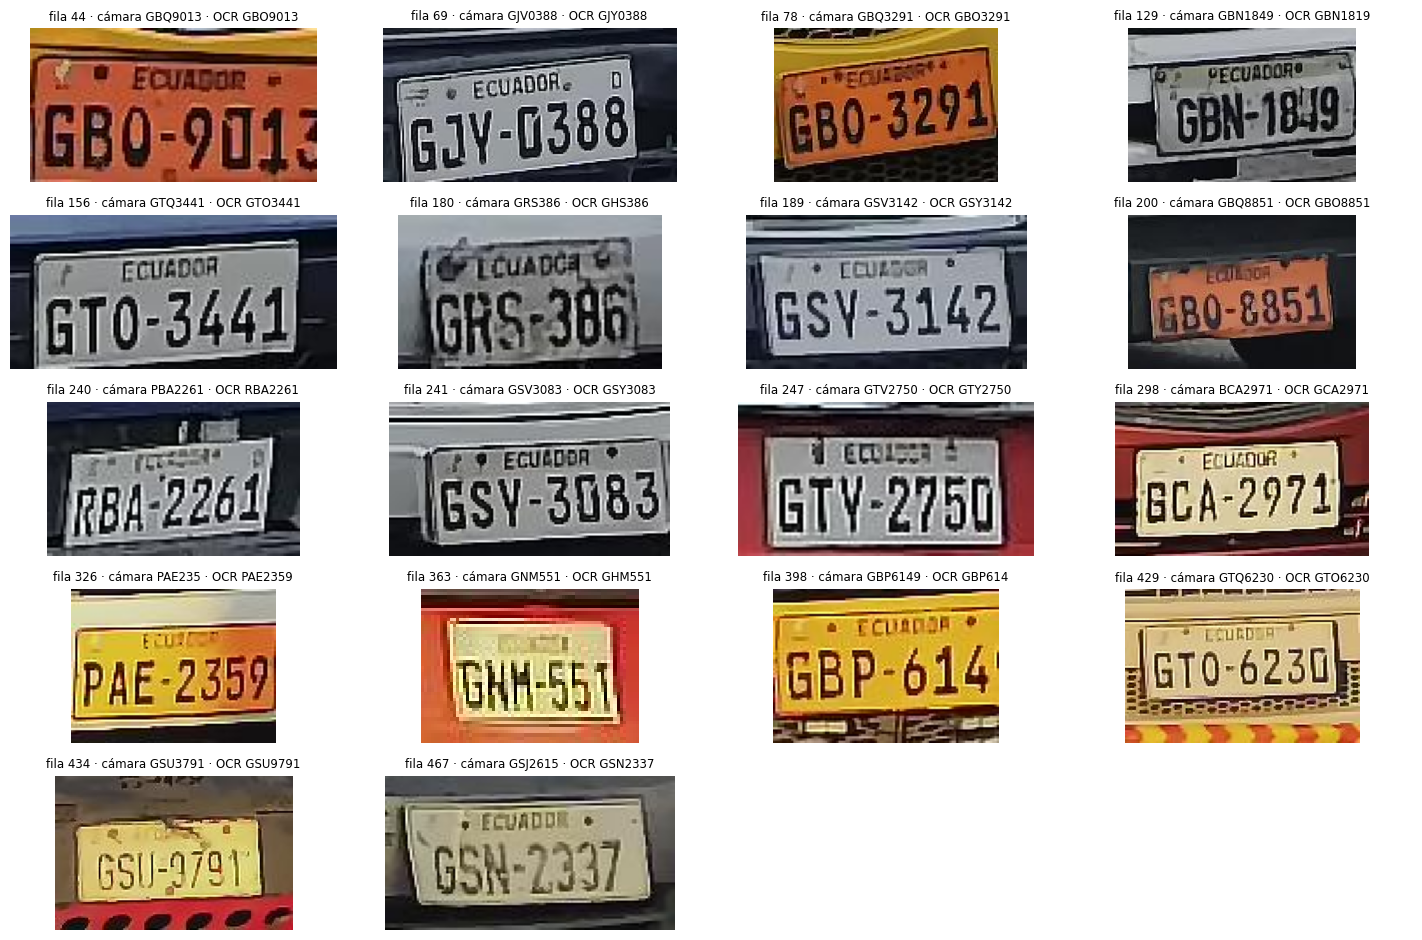

Guardadas en /content/drive/MyDrive/proyecto_integrador_placas/ocr/desacuerdos_camara_ocr.csv. Con ADD_DISAGREEMENTS_TO_SHEET = True se agregan a la hoja de revisión.


In [ ]:
ADD_DISAGREEMENTS_TO_SHEET = False  # True agrega estas imágenes al final de la hoja de revisión (una vez cada una)
DISAGREEMENTS_PATH = OCR_RESULTS_DIR / "desacuerdos_camara_ocr.csv"
REVIEW_COLUMNS = ["n", "fila_gt", "imagen", "texto_actual", "sugerencia", "cambio", "chequeo_visual", "nota", "igual_a",
                  REVIEW_PLATE_COLUMN]


def append_to_review_sheet(rows: list) -> int:
    """Agrega filas al final de la hoja de revisión, salvo las que ya están (por fila_gt). Devuelve cuántas agregó."""
    from google.colab import auth
    import gspread
    from google.auth import default
    auth.authenticate_user()
    credentials, _ = default()
    sheet = gspread.authorize(credentials).open_by_key(REVIEW_SHEET_ID).sheet1
    values = sheet.get_all_values()
    header, body = values[0], values[1:]
    present = {r[header.index("fila_gt")].strip() for r in body}
    last_n = max([int(r[header.index("n")]) for r in body if r[header.index("n")].strip().isdigit()], default=0)
    new = [dict(row) for row in rows if str(row["fila_gt"]) not in present]
    for k, row in enumerate(new, 1):
        row["n"] = last_n + k
    if new:
        sheet.append_rows([[str(row.get(column, "")) for column in header] for row in new], value_input_option="RAW")
    return len(new)


disagreements = None
if savh_ocr is not None:
    in_sheet = set(review["fila_gt"].astype(int))
    camera_only = legible[legible["estado_gt"] == "camara_formato_valido"]
    disagreements = camera_only[~camera_only["correct"] & ~camera_only["fila_gt"].isin(in_sheet)]
    waiting = camera_only[camera_only["fila_gt"].isin(in_sheet)]
    print(f"{len(disagreements)} de {len(camera_only)} legibles con la lectura de la cámara como referencia no coinciden "
          "con el OCR" + (f" ({len(waiting)} más ya están en la hoja, sin respuesta)." if len(waiting) else "."))
    if len(disagreements):
        last_n = max([int(n) for n in review["n"] if str(n).strip().isdigit()], default=0)
        rows = [{"n": last_n + k, "fila_gt": int(r.fila_gt), "imagen": r.image_path, "texto_actual": r.plate_camara,
                 "sugerencia": "", "cambio": "", "chequeo_visual": "desacuerdo cámara/OCR",
                 "nota": f"fast-plate-ocr leyó {r.normalized_text or '(nada)'}", "igual_a": "", REVIEW_PLATE_COLUMN: ""}
                for k, r in enumerate(disagreements.itertuples(index=False), 1)]
        pd.DataFrame(rows, columns=REVIEW_COLUMNS).to_csv(DISAGREEMENTS_PATH, index=False)

        columns = 4
        grid_rows = -(-len(rows) // columns)
        fig, axes = plt.subplots(grid_rows, columns, figsize=(3.6 * columns, 1.9 * grid_rows), squeeze=False)
        for ax in axes.flat:
            ax.axis("off")
        for ax, r in zip(axes.flat, disagreements.itertuples(index=False)):
            ax.imshow(Image.open(SAVH_DIR / r.image_path).convert("RGB"))
            ax.set_title(f"fila {r.fila_gt} · cámara {r.plate_camara} · OCR {r.normalized_text or '—'}", fontsize=8.5)
        plt.tight_layout()
        plt.show()

        if ADD_DISAGREEMENTS_TO_SHEET:
            try:
                added = append_to_review_sheet(rows)
                print(f"{added} filas agregadas al final de la hoja de revisión. Respóndanlas y vuelvan a correr esta sección.")
            except Exception as error:  # sin permiso de escritura o fuera de Colab
                print(f"No se pudo escribir en la hoja ({type(error).__name__}: {error}). "
                      f"Copien las filas de {DISAGREEMENTS_PATH.name} al final de la hoja.")
        else:
            print(f"Guardadas en {DISAGREEMENTS_PATH}. Con ADD_DISAGREEMENTS_TO_SHEET = True se agregan a la hoja de revisión.")

### Confianza del OCR

fast-plate-ocr da la probabilidad de cada carácter que lee, y `plate_confidence` toma la menor entre las letras y dígitos de la placa: una lectura vale lo que su carácter más dudoso. La confianza sirve si separa las lecturas correctas de las equivocadas, y eso mide el **AUROC** (0,5 = no las distingue; 1 = las separa por completo). La tabla de umbrales muestra el costo de usarla: cuántas placas irían a verificación manual y cuántas lecturas equivocadas se seguirían aceptando. La celda usa las confianzas que guardó la celda de lecturas, sin volver a correr el OCR.

Si la confianza sirve, se pone el umbral en `OCR_CONF_MIN` (celda de configuración) y la regla de decisión la usa. El umbral se elige y se mide con los mismos datos, así que el resultado es optimista: hay que confirmarlo con las imágenes de la garita. Para sugerir un umbral, la celda elige el que más reduce las lecturas equivocadas aceptadas sin mandar más del 15 % de las placas a verificación manual (`MAX_MANUAL_SHARE`). Si ninguno lo logra, no sugiere nada.

En la corrida de esta versión el AUROC fue 0,76 y la confianza sí ayuda: con un umbral de 0,9, el 7,5 % de las placas iría a verificación manual y las lecturas equivocadas aceptadas bajarían de 25 a 14. La celda sugiere 0,99: 13 % a verificación manual y 12 equivocadas aceptadas. Hasta la v3.14 este estudio comparaba además dos prompts de GLM-OCR; fast-plate-ocr no usa prompt.

,a verificación manual,EMR de las aceptadas,equivocadas aceptadas
umbral,,,
solo formato,0.0%,93.7%,25
≥ 0.50,0.0%,93.7%,25
≥ 0.70,2.5%,94.3%,22
≥ 0.80,4.0%,95.0%,19
≥ 0.90,7.5%,96.2%,14
≥ 0.95,9.8%,96.4%,13
≥ 0.99,13.0%,96.5%,12


AUROC de la confianza de fast-plate-ocr: 0.76 (399 legibles únicas).
Sugerencia: OCR_CONF_MIN = 0.99 → 13.0% de las placas a verificación manual y 12 lecturas equivocadas aceptadas (sin umbral: 0.0% y 25).


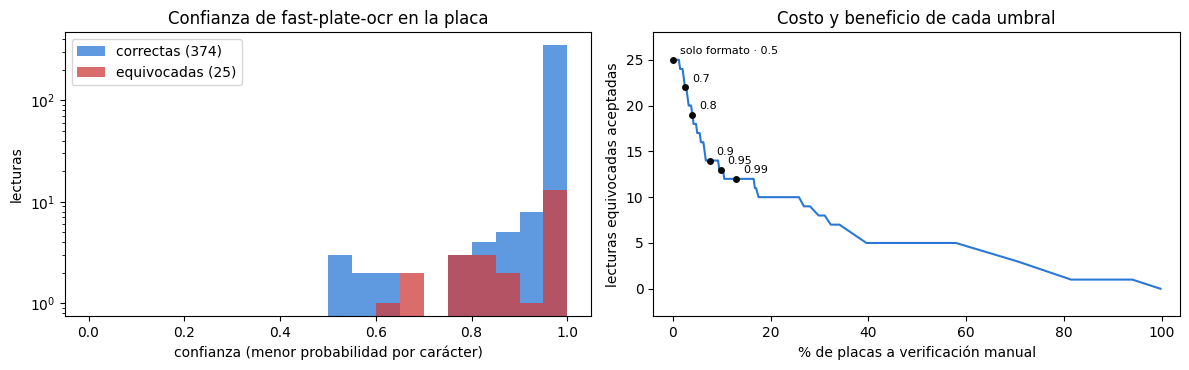

In [ ]:
RUN_OCR_STUDY = True  # False para saltar el estudio
OCR_CONF_THRESHOLDS = [0.5, 0.7, 0.8, 0.9, 0.95, 0.99]
MAX_MANUAL_SHARE = 0.15  # para sugerir un umbral: como mucho 15% de las placas a verificación manual
OCR_STUDY_PATH = OCR_RESULTS_DIR / f"savh_estudio_confianza_{OCR_MODEL_NAME}.json"


def auroc(scores, positives) -> float:
    """Probabilidad de que una lectura correcta tenga más confianza que una equivocada (0,5 = no las distingue)."""
    scores, positives = np.asarray(scores, dtype=float), np.asarray(positives, dtype=bool)
    keep = ~np.isnan(scores)
    scores, positives = scores[keep], positives[keep]
    n_pos, n_neg = int(positives.sum()), int((~positives).sum())
    if n_pos == 0 or n_neg == 0:
        return float("nan")
    ranks = pd.Series(scores).rank().to_numpy()  # empates: rango promedio
    return float((ranks[positives].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))


def threshold_row(group: pd.DataFrame, threshold) -> dict:
    accepted = group["is_valid"] & ((group["conf_ocr"] >= threshold) if threshold is not None else True)
    return {"umbral": "solo formato" if threshold is None else threshold,
            "a verificación manual": float((~accepted).mean()),
            "EMR de las aceptadas": float(group.loc[accepted, "correct"].mean()) if accepted.any() else float("nan"),
            "equivocadas aceptadas": int((accepted & ~group["correct"]).sum())}


ocr_study_summary = {}
if RUN_OCR_STUDY and savh_ocr is not None:
    if legible["conf_ocr"].isna().all():
        print("Las lecturas no tienen confianza: no se puede estudiar.")
    else:
        table = [threshold_row(legible, None)] + [threshold_row(legible, t) for t in OCR_CONF_THRESHOLDS]
        shown = pd.DataFrame(table).assign(umbral=[r["umbral"] if isinstance(r["umbral"], str) else f"≥ {r['umbral']:.2f}"
                                                   for r in table])
        display(shown.set_index("umbral").style.format(
            {"a verificación manual": "{:.1%}", "EMR de las aceptadas": "{:.1%}"}, na_rep="—"))
        options = [row for row in table[1:] if row["a verificación manual"] <= MAX_MANUAL_SHARE]
        best = min(options, key=lambda row: (row["equivocadas aceptadas"], row["a verificación manual"]), default=None)
        area = auroc(legible["conf_ocr"], legible["correct"])
        print(f"AUROC de la confianza de fast-plate-ocr: {area:.2f} ({len(legible)} legibles únicas).")
        if best and best["equivocadas aceptadas"] < table[0]["equivocadas aceptadas"]:
            print(f"Sugerencia: OCR_CONF_MIN = {best['umbral']} → {best['a verificación manual']:.1%} de las placas a "
                  f"verificación manual y {best['equivocadas aceptadas']} lecturas equivocadas aceptadas "
                  f"(sin umbral: {table[0]['a verificación manual']:.1%} y {table[0]['equivocadas aceptadas']}).")
            ocr_study_summary["umbral_sugerido"] = best["umbral"]
        else:
            print(f"Ningún umbral baja las lecturas equivocadas aceptadas sin mandar más de {MAX_MANUAL_SHARE:.0%} de las "
                  "placas a verificación manual: con estos datos, la confianza no aporta.")
        ocr_study_summary.update({"modelo_ocr": f"fast-plate-ocr {OCR_MODEL_NAME}", "auroc": area, "umbrales": table})

        fig, (ax_hist, ax_cost) = plt.subplots(1, 2, figsize=(12, 3.8))
        bins = np.linspace(0, 1, 21)
        for correct, color, label in ((True, "#2a78d6", "correctas"), (False, "#d03b3b", "equivocadas")):
            values = legible.loc[legible["correct"] == correct, "conf_ocr"].dropna()
            ax_hist.hist(values, bins=bins, color=color, alpha=0.75, label=f"{label} ({len(values)})")
        ax_hist.set(title="Confianza de fast-plate-ocr en la placa", xlabel="confianza (menor probabilidad por carácter)",
                    ylabel="lecturas", yscale="log")
        ax_hist.legend()
        grid = np.unique(np.concatenate([[0.0], legible["conf_ocr"].dropna().to_numpy(), [1.0]]))
        curve = [threshold_row(legible, t) for t in grid]
        ax_cost.plot([100 * r["a verificación manual"] for r in curve], [r["equivocadas aceptadas"] for r in curve],
                     color="#2a78d6")
        points = {}  # umbrales que caen en el mismo punto comparten etiqueta
        for row in table:
            key = (100 * row["a verificación manual"], row["equivocadas aceptadas"])
            points.setdefault(key, []).append(row["umbral"] if isinstance(row["umbral"], str) else f"{row['umbral']:g}")
        for (x, y), names in points.items():
            ax_cost.plot(x, y, "o", color="#0b0b0b", ms=4)
            ax_cost.annotate(" · ".join(names), (x, y), textcoords="offset points", fontsize=8,
                             xytext=(-5, 4) if x > 80 else (5, 4), ha="right" if x > 80 else "left")
        ax_cost.set(title="Costo y beneficio de cada umbral", xlabel="% de placas a verificación manual",
                    ylabel="lecturas equivocadas aceptadas")
        ax_cost.margins(x=0.04, y=0.12)
        plt.tight_layout()
        fig.savefig(OCR_RESULTS_DIR / f"estudio_confianza_{OCR_MODEL_NAME}.png", dpi=200, bbox_inches="tight")
        plt.show()

    OCR_STUDY_PATH.write_text(json.dumps(ocr_study_summary, indent=2, ensure_ascii=False, default=_to_json))

### Lista de placas autorizadas

Un CSV con una placa por línea en la carpeta de Drive (`authorized_plates.csv`). Si no existe se crea vacío para que el pipeline no falle. **La lista real sale de la base de la planta**: en la sección 6 se le suman las placas activas de `camiones_postgres.sql`, así que este CSV queda para excepciones (por ejemplo, un vehículo de visita que no está en la base). La lista simulada con la que se evalúa la regla en SAVH (más abajo) se guarda aparte, en `ocr/authorized_plates_simulada.csv`, y no reemplaza a esta. Las placas se pasan al formato XXX-0000 con `format_plate`, así que `GBA-1234`, `gba1234` y `GBA 1234` cuentan como la misma, igual que `GMS-429` y `GMS-0429`.

In [ ]:
# format_plate y clean_plate_text están en la celda de normalización.


def load_authorized_plates(path: Path) -> set:
    if not path.exists():
        path.write_text("")
        print(f"Aviso: {path} no existía; se creó vacío. Agrega placas autorizadas, una por línea.")
    with open(path, newline="") as f:
        plates = {format_plate(row[0]) for row in csv.reader(f) if row and row[0].strip()}  # XXX-0000
    return plates - {"PLACA", "PLATE"}  # por si el CSV trae encabezado


def edit_distance_leq_1(a: str, b: str) -> bool:
    if abs(len(a) - len(b)) > 1:
        return False
    return Levenshtein.distance(a, b) <= 1


AUTHORIZED_PLATES = load_authorized_plates(AUTHORIZED_LIST_PATH)
print(f"{len(AUTHORIZED_PLATES)} placas autorizadas en {AUTHORIZED_LIST_PATH}")

0 placas autorizadas en /content/drive/MyDrive/proyecto_integrador_placas/authorized_plates.csv


### Regla de decisión
`decide_access` devuelve uno de tres estados y revisa las condiciones en este orden:

1. formato inválido, confianza de detección menor que el umbral de decisión del detector o, si está activada, confianza del OCR baja → `VERIFICACION_MANUAL`;
2. coincidencia exacta con una placa autorizada → `AUTORIZADO`;
3. a un carácter de una placa autorizada (distancia de Levenshtein ≤ 1) → `VERIFICACION_MANUAL`;
4. si no coincide con nada → `NO_REGISTRADO`.

El umbral de detección no es un 0,30 fijo: el detector usa su `conf_decision` calibrado en *val* (sección 3). La confianza del OCR solo cuenta si `OCR_CONF_MIN` tiene un valor (por defecto `None`); el estudio de confianza de la sección 5 sugiere uno. En el pipeline de video (sección 6) la lista de autorizados incluye además las placas activas de la base de la planta, y una placa registrada pero inactiva pasa de `NO_REGISTRADO` a `VERIFICACION_MANUAL`.

In [ ]:
def decide_access(normalized_text: str, is_valid: bool, det_conf: float, authorized: set, conf_min: float,
                  ocr_conf: float = 1.0, ocr_conf_min=None) -> str:
    """Regla de tres estados. `conf_min` es el umbral de decisión calibrado para el detector; `ocr_conf_min`, el de la
    confianza del OCR (None = no se usa; una confianza NaN cuenta como baja)."""
    low_ocr_conf = ocr_conf_min is not None and not ocr_conf >= ocr_conf_min
    if not is_valid or det_conf < conf_min or low_ocr_conf:
        return "VERIFICACION_MANUAL"

    if normalized_text in authorized:
        return "AUTORIZADO"

    if any(edit_distance_leq_1(normalized_text, p) for p in authorized):
        return "VERIFICACION_MANUAL"

    return "NO_REGISTRADO"

### Evaluación de la regla con una lista simulada (SAVH)

Para medir la regla hacen falta lecturas cuya placa real se conozca. Las legibles únicas de SAVH tienen referencia, pero sus vehículos no están en la base de la planta, así que esta celda arma una **lista simulada**: la mitad de las placas distintas, elegidas al azar con semilla fija. La lista se guarda en `ocr/authorized_plates_simulada.csv` y no se usa en ninguna otra parte del notebook. Como los recortes de SAVH no pasan por el detector, la confianza de detección se toma como 1.

Para cada imagen se compara la decisión con la que corresponde a la placa real:

- **Falso autorizado**: la placa real no está en la lista y la regla dice `AUTORIZADO`. Es el error que el sistema debe evitar.
- **Rechazo indebido**: la placa real está en la lista y la regla dice `NO_REGISTRADO`.
- **Verificación manual**: el costo de la regla, porque un guardia tiene que mirar.

Una lista al azar es un caso favorable: una lectura equivocada casi nunca coincide justo con otra placa de la lista. Por eso se agrega un **peor caso**, en el que toda lectura equivocada con formato válido coincide con una placa autorizada (por ejemplo, en una flota con placas consecutivas). Si el estudio anterior sugirió un umbral de confianza, la regla se evalúa también con ese umbral.

In [ ]:
SIMULATED_AUTHORIZED_PATH = OCR_RESULTS_DIR / "authorized_plates_simulada.csv"
SIMULATED_AUTHORIZED_SHARE = 0.5  # fracción de las placas distintas de SAVH que se toman como autorizadas
DECISIONS = ["AUTORIZADO", "VERIFICACION_MANUAL", "NO_REGISTRADO"]


def evaluate_rule(frame: pd.DataFrame, authorized: set, ocr_conf_min) -> dict:
    """Decisiones de la regla sobre las lecturas de SAVH frente a la placa real (detección con confianza 1)."""
    decisions = pd.Series([decide_access(format_plate(plate), valid, 1.0, authorized, 0.0, conf, ocr_conf_min)
                           for plate, valid, conf
                           in zip(frame["normalized_text"], frame["is_valid"], frame["conf_ocr"])], index=frame.index)
    is_authorized = frame["plate_gt"].map(format_plate).isin(authorized)
    accepted = frame["is_valid"] & ((frame["conf_ocr"] >= ocr_conf_min) if ocr_conf_min is not None else True)
    return {
        "tabla": pd.crosstab(is_authorized.map({True: "autorizada", False: "no autorizada"}).rename("placa real"),
                             decisions.rename("decisión")).reindex(columns=DECISIONS, fill_value=0),
        "falsos_autorizados": int(((decisions == "AUTORIZADO") & ~is_authorized).sum()),
        "no_autorizadas": int((~is_authorized).sum()),
        "rechazos_indebidos": int(((decisions == "NO_REGISTRADO") & is_authorized).sum()),
        "autorizadas": int(is_authorized.sum()),
        "verificacion_manual": float((decisions == "VERIFICACION_MANUAL").mean()),
        "peor_caso_falsos_autorizados": float((accepted & ~frame["correct"]).mean()),
    }


if savh_ocr is not None:
    distinct = sorted({format_plate(plate) for plate in legible["plate_gt"]})  # XXX-0000, como en el pipeline
    simulated = set(random.Random(SEED).sample(distinct, round(len(distinct) * SIMULATED_AUTHORIZED_SHARE)))
    SIMULATED_AUTHORIZED_PATH.write_text("placa\n" + "\n".join(sorted(simulated)) + "\n")
    print(f"Lista simulada: {len(simulated)} de {len(distinct)} placas distintas de SAVH, en {SIMULATED_AUTHORIZED_PATH}")

    frame = legible[["image_path", "plate_gt", "normalized_text", "is_valid", "correct", "conf_ocr"]].copy()
    variants = {f"Regla actual (OCR_CONF_MIN = {OCR_CONF_MIN})": OCR_CONF_MIN}
    suggested = (globals().get("ocr_study_summary") or {}).get("umbral_sugerido")
    if suggested is not None and suggested != OCR_CONF_MIN:
        variants[f"Con el umbral sugerido (OCR_CONF_MIN = {suggested})"] = suggested

    simulation = {}
    for label, threshold in variants.items():
        result = evaluate_rule(frame, simulated, threshold)
        simulation[label] = result
        print(f"\n{label}, {len(frame)} imágenes:")
        display(result["tabla"])
        print(f"Falsos autorizados: {result['falsos_autorizados']} de {result['no_autorizadas']} no autorizadas · "
              f"rechazos indebidos: {result['rechazos_indebidos']} de {result['autorizadas']} autorizadas · "
              f"verificación manual: {result['verificacion_manual']:.1%} de las imágenes.\n"
              f"Peor caso: hasta {result['peor_caso_falsos_autorizados']:.1%} de los vehículos no autorizados entrarían "
              "como autorizados.")
    (OCR_RESULTS_DIR / "decision_simulada.json").write_text(json.dumps(
        {label: {**{k: v for k, v in r.items() if k != "tabla"}, "tabla": r["tabla"].to_dict()}
         for label, r in simulation.items()}, indent=2, ensure_ascii=False, default=_to_json))

Lista simulada: 178 de 357 placas distintas de SAVH, en /content/drive/MyDrive/proyecto_integrador_placas/ocr/authorized_plates_simulada.csv

Regla actual (OCR_CONF_MIN = None), 399 imágenes:


decisión,AUTORIZADO,VERIFICACION_MANUAL,NO_REGISTRADO
placa real,,,
autorizada,184,12,1
no autorizada,0,4,198


Falsos autorizados: 0 de 202 no autorizadas · rechazos indebidos: 1 de 197 autorizadas · verificación manual: 4.0% de las imágenes.
Peor caso: hasta 6.3% de los vehículos no autorizados entrarían como autorizados.

Con el umbral sugerido (OCR_CONF_MIN = 0.99), 399 imágenes:


decisión,AUTORIZADO,VERIFICACION_MANUAL,NO_REGISTRADO
placa real,,,
autorizada,165,31,1
no autorizada,0,31,171


Falsos autorizados: 0 de 202 no autorizadas · rechazos indebidos: 1 de 197 autorizadas · verificación manual: 15.5% de las imágenes.
Peor caso: hasta 3.0% de los vehículos no autorizados entrarían como autorizados.


### Registro de decisiones
Define el registro CSV que usa el pipeline de video: un archivo por corrida (`resultados/<corrida>_decisions_log.csv`), que se reescribe en cada corrida para no mezclar resultados. Cada placa decidida es una fila con:

- `model`, `frame_index` (cuadro del recorte que se leyó), `track_id` y la caja (`x1`, `y1`, `x2`, `y2`);
- `det_conf` (confianza del detector), `raw_text` (texto del OCR), `normalized_text`, `is_valid` (formato válido) y `ocr_conf` (confianza del OCR);
- `status` (decisión de acceso), `det_ms` y `ocr_ms` (tiempos de detección y de OCR de esa decisión);
- `trigger` (motivo de la lectura), `plate_area_px` (área del recorte leído) y `decision_frame` (cuadro en que se decidió);
- `ocr_lecturas`: lo que leyó el OCR en cada recorte que entró en la votación de la placa (sección 6).

La sección 7a usa este registro para medir aciertos contra el video anotado.

In [ ]:
LOG_FIELDS = ["model", "frame_index", "track_id", "x1", "y1", "x2", "y2", "det_conf", "raw_text", "normalized_text",
              "is_valid", "ocr_conf", "status", "det_ms", "ocr_ms", "trigger", "plate_area_px", "decision_frame",
              "ocr_lecturas"]


def log_path_for(name: str, tag: str = "") -> Path:
    """Registro de decisiones de una corrida; `tag` es el sufijo de una variante de CONFIGS ("" en la corrida principal)."""
    return RESULTS_DIR / f"{run_name(name)}{tag}_decisions_log.csv"


def start_log(name: str, tag: str = "") -> Path:
    path = log_path_for(name, tag)
    with open(path, "w", newline="") as f:
        csv.writer(f).writerow(LOG_FIELDS)
    return path


def log_decision(path: Path, row: dict) -> None:
    with open(path, "a", newline="") as f:
        csv.writer(f).writerow([row[field] for field in LOG_FIELDS])

## 8. Resultados finales de YOLO11-s

Todo se lee desde la carpeta de Drive, así que esta sección funciona en una sesión nueva: corre la sección 0 y luego esta celda. Las filas de partes que todavía no corriste no aparecen.

La tabla compara cada métrica con su **meta del proyecto** (mAP@0.5 ≥ 0,85 en *test*, EMR ≥ 80 % y ≤ 1 s por decisión). Se guarda en `resultados/resumen_yolo11_<preset>.csv` y el gráfico en `figuras/resumen_yolo11_<preset>.png` (200 dpi, listo para el informe):

- métricas de detección en *test* y meta de mAP@0.5;
- mAP@0.5:0.95 por tamaño de placa;
- aprendizaje por época (mAP de validación);
- F1 en función de la confianza, con el umbral calibrado en *val*.


valor     meta  \
sección              métrica                                                
Detección (test)     mAP@0.5                               0.972  ≥ 0.850   
                     mAP@0.5:0.95                          0.693        —   
                     Precisión (umbral calibrado)          0.986        —   
                     Recall (umbral calibrado)             0.956        —   
                     F1 (umbral calibrado)                 0.971        —   
                     mAP@0.5:0.95 placas pequeñas          0.481        —   
                     mAP@0.5:0.95 placas medianas          0.729        —   
                     mAP@0.5:0.95 placas grandes           0.744        —   
Umbrales (val)       Umbral de seguimiento (máx. F1)        0.30        —   
                     Umbral de decisión (precisión ≥ 95%)   0.30        —   
OCR (SAVH Guayaquil) EMR en legibles únicas                93.7%  ≥ 80.0%   
Velocidad            Latencia media (ms)                    22.2        —   
                     Latencia p95 (ms)                      22.7        —   
                     FPS (lote 1)                           45.0        —   
Tamaño               Parámetros (M)                          9.4        —   
                     GFLOPs                                 21.4        —   
Entrenamiento        Épocas corridas                          40        —   
                     Mejor época                              40        —   
                     Horas de entrenamiento                 0.70        —   
                     Memoria GPU pico (GB)                   6.9        —   
Video                Tracks confirmados                       52        —   
                     Placas leídas                            52        —   
                     Lecturas con formato válido              25        —   
                     FPS del pipeline                       66.1        —   
                     s por decisión (detección + OCR)      0.090  ≤ 1.000   

                                                          cumple  
sección              métrica                                      
Detección (test)     mAP@0.5                                  sí  
                     mAP@0.5:0.95                              —  
                     Precisión (umbral calibrado)              —  
                     Recall (umbral calibrado)                 —  
                     F1 (umbral calibrado)                     —  
                     mAP@0.5:0.95 placas pequeñas              —  
                     mAP@0.5:0.95 placas medianas              —  
                     mAP@0.5:0.95 placas grandes               —  
Umbrales (val)       Umbral de seguimiento (máx. F1)           —  
                     Umbral de decisión (precisión ≥ 95%)      —  
OCR (SAVH Guayaquil) EMR en legibles únicas                   sí  
Velocidad            Latencia media (ms)                       —  
                     Latencia p95 (ms)                         —  
                     FPS (lote 1)                              —  
Tamaño               Parámetros (M)                            —  
                     GFLOPs                                    —  
Entrenamiento        Épocas corridas                           —  
                     Mejor época                               —  
                     Horas de entrenamiento                    —  
                     Memoria GPU pico (GB)                     —  
Video                Tracks confirmados                        —  
                     Placas leídas                             —  
                     Lecturas con formato válido               —  
                     FPS del pipeline                          —  
                     s por decisión (detección + OCR)         sí

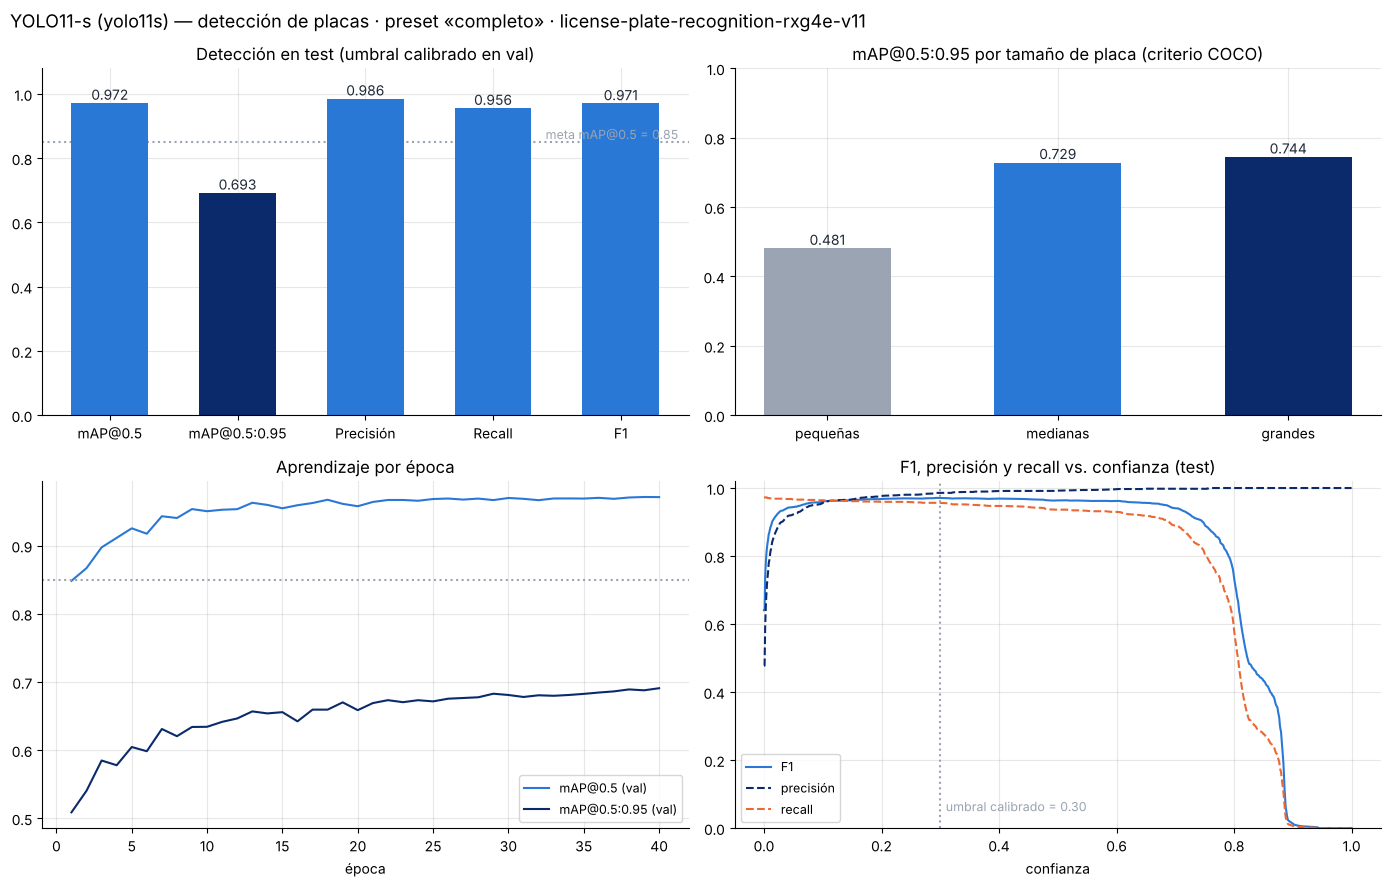

Preset «completo» — resultados finales de YOLO11-s
- mAP@0.5 en test: 0.972 → cumple la meta ≥ 0.85
- mAP@0.5:0.95 en test: 0.693 · en placas pequeñas: 0.481 (el caso más difícil)
- Recall al umbral calibrado: 0.956 · precisión: 0.986
- Latencia media: 22.2 ms por imagen en GPU (FP16) · 9.4 M parámetros
- Entrenamiento: 0.70 h (40 épocas)
- OCR en SAVH (fast-plate-ocr cct-s-v2-global-model): EMR 93.7% en 399 legibles únicas, meta ≥ 80% (69 referencias todavía sin confirmar).
- Video de la garita: 90 ms por decisión (detección + OCR) → cumple la meta ≤ 1 s
- EMR punta a punta: pendiente de la referencia anotada (sección 7).
Tabla: /content/drive/MyDrive/proyecto_integrador_placas/experimentos/license-plate-recognition-rxg4e-v11/resultados/resumen_yolo11_completo.csv · gráfico: /content/drive/MyDrive/proyecto_integrador_placas/experimentos/license-plate-recognition-rxg4e-v11/figuras/resumen_yolo11_completo.png


In [ ]:
# 8 · Resultados finales de YOLO11-s: se leen de Drive (no entrena ni evalúa de nuevo)
MODEL = "YOLO11"


def collect_results(name: str = MODEL) -> dict:
    flag = RUNS_DIR / run_name(name) / "train_done.json"
    results = {"entrenamiento": json.loads(flag.read_text()) if flag.exists() else {}}
    for kind in ("umbrales", "test", "tamanos", "velocidad", "video", "sistema_video", "e2e_imagenes"):
        results[kind] = load_result(name, kind) or {}
    savh_path = OCR_RESULTS_DIR / "savh_resumen.json"
    results["ocr_savh"] = json.loads(savh_path.read_text()) if savh_path.exists() else {}
    return results


# (sección, métrica, origen, campo, formato, meta, True = la meta es un mínimo / False = un máximo)
SUMMARY_ROWS = [
    ("Detección (test)", "mAP@0.5", "test", "mAP50", "{:.3f}", TARGET_MAP50, True),
    ("Detección (test)", "mAP@0.5:0.95", "test", "mAP50-95", "{:.3f}", None, None),
    ("Detección (test)", "Precisión (umbral calibrado)", "test", "precision", "{:.3f}", None, None),
    ("Detección (test)", "Recall (umbral calibrado)", "test", "recall", "{:.3f}", None, None),
    ("Detección (test)", "F1 (umbral calibrado)", "test", "f1", "{:.3f}", None, None),
    ("Detección (test)", "mAP@0.5:0.95 placas pequeñas", "tamanos", "mAP50-95_pequenas", "{:.3f}", None, None),
    ("Detección (test)", "mAP@0.5:0.95 placas medianas", "tamanos", "mAP50-95_medianas", "{:.3f}", None, None),
    ("Detección (test)", "mAP@0.5:0.95 placas grandes", "tamanos", "mAP50-95_grandes", "{:.3f}", None, None),
    ("Umbrales (val)", "Umbral de seguimiento (máx. F1)", "umbrales", "conf_track", "{:.2f}", None, None),
    ("Umbrales (val)", "Umbral de decisión (precisión ≥ 95%)", "umbrales", "conf_decision", "{:.2f}", None, None),
    ("OCR (SAVH Guayaquil)", "EMR en legibles únicas", "ocr_savh", "emr_legibles_unicas", "{:.1%}", TARGET_EMR, True),
    ("Velocidad", "Latencia media (ms)", "velocidad", "latencia_ms_media", "{:.1f}", None, None),
    ("Velocidad", "Latencia p95 (ms)", "velocidad", "latencia_ms_p95", "{:.1f}", None, None),
    ("Velocidad", "FPS (lote 1)", "velocidad", "fps", "{:.1f}", None, None),
    ("Tamaño", "Parámetros (M)", "velocidad", "parametros_M", "{:.1f}", None, None),
    ("Tamaño", "GFLOPs", "velocidad", "gflops", "{:.1f}", None, None),
    ("Entrenamiento", "Épocas corridas", "entrenamiento", "epocas_corridas", "{:.0f}", None, None),
    ("Entrenamiento", "Mejor época", "entrenamiento", "mejor_epoca", "{:.0f}", None, None),
    ("Entrenamiento", "Horas de entrenamiento", "entrenamiento", "horas_entrenamiento", "{:.2f}", None, None),
    ("Entrenamiento", "Memoria GPU pico (GB)", "entrenamiento", "gpu_mem_pico_gb", "{:.1f}", None, None),
    ("Video", "Tracks confirmados", "video", "tracks_confirmados", "{:.0f}", None, None),
    ("Video", "Placas leídas", "video", "placas_leidas", "{:.0f}", None, None),
    ("Video", "Lecturas con formato válido", "video", "formato_valido", "{:.0f}", None, None),
    ("Video", "FPS del pipeline", "video", "fps_pipeline", "{:.1f}", None, None),
    ("Video", "s por decisión (detección + OCR)", "video", "e2e_ms_por_placa_media", "{:.3f}", TARGET_E2E_S, False),
    ("Sistema (video anotado)", "EMR por lectura", "sistema_video", "emr_por_lectura", "{:.1%}", TARGET_EMR, True),
    ("Sistema (video anotado)", "Falsos autorizados", "sistema_video", "falsos_autorizados", "{:.0f}", None, None),
    ("Sistema (imágenes)", "EMR", "e2e_imagenes", "emr", "{:.1%}", TARGET_EMR, True),
    ("Sistema (imágenes)", "Segundos por imagen (media)", "e2e_imagenes", "e2e_s_media", "{:.2f}", TARGET_E2E_S, False),
]


def to_float(value) -> float:
    try:
        return float(value)
    except (TypeError, ValueError):
        return float("nan")


final = collect_results()
rows = []
for section, label, kind, field, fmt, target, is_minimum in SUMMARY_ROWS:
    value = to_float(final[kind].get(field))
    if field == "e2e_ms_por_placa_media":
        value /= 1000  # ms → s, para compararlo con la meta de segundos
    if np.isnan(value):
        continue
    meets = "—" if target is None else ("sí" if (value >= target if is_minimum else value <= target) else "no")
    goal = "—" if target is None else ("≥ " if is_minimum else "≤ ") + fmt.format(target)
    rows.append({"sección": section, "métrica": label, "valor": fmt.format(value), "meta": goal, "cumple": meets,
                 "valor_num": value})
summary = pd.DataFrame(rows).set_index(["sección", "métrica"])
summary.to_csv(RESULTS_DIR / f"resumen_yolo11_{TRAINING_PRESET}.csv")
display(summary.drop(columns="valor_num"))

# ---- Gráficos ---------------------------------------------------------------------------------
INK, BLUE, NAVY, MUTED = "#1f2937", MODEL_COLORS[MODEL], "#0b2a6b", "#9aa4b2"
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
ax = axes[0, 0]
labels = ["mAP@0.5", "mAP@0.5:0.95", "Precisión", "Recall", "F1"]
values = [to_float(final["test"].get(k)) for k in ("mAP50", "mAP50-95", "precision", "recall", "f1")]
bars = ax.bar(labels, values, color=[BLUE, NAVY, BLUE, BLUE, BLUE], width=0.6, zorder=2)
ax.axhline(TARGET_MAP50, color=MUTED, linestyle=":", zorder=1)
ax.text(4.45, TARGET_MAP50 + 0.01, f"meta mAP@0.5 = {TARGET_MAP50}", ha="right", color=MUTED, fontsize=9)
for bar, value in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.01, f"{value:.3f}", ha="center", color=INK, fontsize=10)
ax.set_ylim(0, 1.08)
ax.set_title("Detección en test (umbral calibrado en val)")

ax = axes[0, 1]
sizes = ["pequeñas", "medianas", "grandes"]
size_values = [to_float(final["tamanos"].get(f"mAP50-95_{k}")) for k in ("pequenas", "medianas", "grandes")]
bars = ax.bar(sizes, size_values, color=[MUTED, BLUE, NAVY], width=0.55, zorder=2)
for bar, value in zip(bars, size_values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.01, f"{value:.3f}", ha="center", color=INK, fontsize=10)
ax.set_ylim(0, 1.0)
ax.set_title("mAP@0.5:0.95 por tamaño de placa (criterio COCO)")

ax = axes[1, 0]
history_path = RUNS_DIR / run_name(MODEL) / "results.csv"
if history_path.exists():
    history = pd.read_csv(history_path)
    history.columns = history.columns.str.strip()
    ax.plot(history["epoch"], history["metrics/mAP50(B)"], color=BLUE, label="mAP@0.5 (val)")
    ax.plot(history["epoch"], history["metrics/mAP50-95(B)"], color=NAVY, label="mAP@0.5:0.95 (val)")
    ax.axhline(TARGET_MAP50, color=MUTED, linestyle=":")
    ax.legend(fontsize=9)
ax.set_xlabel("época")
ax.set_title("Aprendizaje por época")

ax = axes[1, 1]
curves_path = RESULTS_DIR / f"{run_name(MODEL)}_curvas_test.npz"
if curves_path.exists():
    curves = np.load(curves_path)
    ax.plot(curves["grid"], curves["f1"], color=BLUE, label="F1")
    ax.plot(curves["grid"], curves["precision"], color=NAVY, linestyle="--", label="precisión")
    ax.plot(curves["grid"], curves["recall"], color="#eb6834", linestyle="--", label="recall")
    threshold = to_float(final["umbrales"].get("conf_decision"))
    if not np.isnan(threshold):
        ax.axvline(threshold, color=MUTED, linestyle=":")
        ax.text(threshold + 0.01, 0.05, f"umbral calibrado = {threshold:.2f}", color=MUTED, fontsize=9)
    ax.set_ylim(0, 1.02)
    ax.legend(fontsize=9, loc="lower left")
ax.set_xlabel("confianza")
ax.set_title("F1, precisión y recall vs. confianza (test)")
for ax in axes.ravel():
    ax.grid(alpha=0.3, zorder=0)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(f"YOLO11-s ({Path(DETECTORS[MODEL]['weights']).stem}) — detección de placas · preset «{TRAINING_PRESET}» · "
             f"{DATASET_ID}", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
summary_png = FIGURES_DIR / f"resumen_yolo11_{TRAINING_PRESET}.png"
fig.savefig(summary_png, dpi=200)
plt.show()

# ---- Lectura rápida ---------------------------------------------------------------------------
def fmt_metric(kind, field, fmt):
    value = to_float(final[kind].get(field))
    return "—" if np.isnan(value) else fmt.format(value)


lines = [f"Preset «{TRAINING_PRESET}» — {'resultados preliminares' if TRAINING_PRESET == 'rapido' else 'resultados finales'} de YOLO11-s"]
map50 = to_float(final["test"].get("mAP50"))
if not np.isnan(map50):
    lines.append(f"- mAP@0.5 en test: {map50:.3f} → {'cumple' if map50 >= TARGET_MAP50 else 'no cumple'} la meta ≥ {TARGET_MAP50:.2f}")
lines.append(f"- mAP@0.5:0.95 en test: {fmt_metric('test', 'mAP50-95', '{:.3f}')} · en placas pequeñas: "
             f"{fmt_metric('tamanos', 'mAP50-95_pequenas', '{:.3f}')} (el caso más difícil)")
lines.append(f"- Recall al umbral calibrado: {fmt_metric('test', 'recall', '{:.3f}')} · precisión: {fmt_metric('test', 'precision', '{:.3f}')}")
lines.append(f"- Latencia media: {fmt_metric('velocidad', 'latencia_ms_media', '{:.1f} ms')} por imagen en GPU (FP16) · "
             f"{fmt_metric('velocidad', 'parametros_M', '{:.1f}')} M parámetros")
lines.append(f"- Entrenamiento: {fmt_metric('entrenamiento', 'horas_entrenamiento', '{:.2f} h')} "
             f"({fmt_metric('entrenamiento', 'epocas_corridas', '{:.0f}')} épocas)")
if final["ocr_savh"]:
    unconfirmed = final["ocr_savh"].get("sugerencias_sin_confirmar", 0)
    lines.append(f"- OCR en SAVH ({final['ocr_savh'].get('modelo_ocr', 'fast-plate-ocr')}): EMR "
                 f"{final['ocr_savh']['emr_legibles_unicas']:.1%} en {final['ocr_savh']['n_legibles_unicas']} legibles únicas, "
                 f"meta ≥ {TARGET_EMR:.0%}" + (f" ({unconfirmed} referencias todavía sin confirmar)." if unconfirmed else "."))
e2e_ms = to_float(final["video"].get("e2e_ms_por_placa_media"))
if not np.isnan(e2e_ms):
    lines.append(f"- Video de la garita: {e2e_ms:.0f} ms por decisión (detección + OCR) → "
                 f"{'cumple' if e2e_ms / 1000 <= TARGET_E2E_S else 'no cumple'} la meta ≤ {TARGET_E2E_S:.0f} s")
if not final["sistema_video"] and not final["e2e_imagenes"]:
    lines.append("- EMR punta a punta: pendiente de la referencia anotada (sección 7).")
lines.append(f"Tabla: {RESULTS_DIR / f'resumen_yolo11_{TRAINING_PRESET}.csv'} · gráfico: {summary_png}")
print("\n".join(lines))
